# Groundwater Forecasting — Model Evaluation Report

## Objective
The objective of this notebook is to provide a final, rigorous scientific evaluation of the groundwater prediction component. It answers: "How systematically and reliably does the groundwater forecasting system predict the next valid Maharashtra groundwater observation?"

## Context
- **Prediction Target**: Next valid groundwater observation ($X_{t+1}$)
- **Geography**: Maharashtra, India
- **Production Forecasting Method**: Persistence baseline (predicted value = latest observed value). Chosen for its robustness, mathematical transparency, and immunity to missing history/data gaps.
- **Experimental Models**: HistGradientBoosting and XGBoost, incorporating meteorological data (Precipitation, ET0).
- **Evaluation Methodology**: Chronological, target-isolated split preventing any data leakage.

*An executive summary of findings is automatically generated at the conclusion of this notebook.*

In [3]:
%pip install xgboost

     ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
     ---------------------------------------- 0.2/101.7 MB 5.3 MB/s eta 0:00:20
     ---------------------------------------- 0.4/101.7 MB 4.6 MB/s eta 0:00:23
     ---------------------------------------- 0.5/101.7 MB 4.2 MB/s eta 0:00:25
     ---------------------------------------- 0.7/101.7 MB 3.9 MB/s eta 0:00:27
     ---------------------------------------- 0.7/101.7 MB 3.1 MB/s eta 0:00:34
     ---------------------------------------- 0.8/101.7 MB 3.0 MB/s eta 0:00:35
     ---------------------------------------- 0.9/101.7 MB 2.8 MB/s eta 0:00:37
     ---------------------------------------- 1.0/101.7 MB 2.6 MB/s eta 0:00:39
     ---------------------------------------- 1.0/101.7 MB 2.5 MB/s eta 0:00:41
     ---------------------------------------- 1.1/101.7 MB 2.4 MB/s eta 0:00:43
     ---------------------------------------- 1.2/101.7 MB 2.2 MB/s eta 0:00:46
     ---------------------------------------- 1


[notice] A new release of pip is available: 23.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
import os
import sys
from pathlib import Path
from datetime import datetime
from xgboost import XGBRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, median_absolute_error

# Determine project root
try:
    # If running as script
    PROJECT_ROOT = Path(__file__).resolve().parent.parent
except NameError:
    # If running in notebook
    PROJECT_ROOT = Path(os.getcwd()).parent

if PROJECT_ROOT.name != "NEW":
    # Fallback to current dir if we are already in NEW
    PROJECT_ROOT = Path(os.getcwd())

print(f"Project root identified as: {PROJECT_ROOT}")

# Create output directories
REPORT_DIR = PROJECT_ROOT / "reports" / "model_evaluation"
FIGURES_DIR = REPORT_DIR / "figures"
TABLES_DIR = REPORT_DIR / "tables"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 300
plt.rcParams['savefig.dpi'] = 300


Project root identified as: d:\Projects ALL\DWLR_GRW_INDIA\NEW


In [5]:
# SCIENTIFIC VALIDATION - PRE CHECK
validation_passed = True
validation_errors = []

def assert_check(condition, message):
    global validation_passed
    if not condition:
        validation_passed = False
        validation_errors.append(message)
        print(f"FAIL: {message}")
    else:
        print(f"PASS: {message}")


## 2. Project / Dataset Context
Loading actual dataset and reporting statistics.

Number of Maharashtra candidate sites: 1011
Number of valid observations: 210468
Date range: 2025-12-31 to 2026-05-29
Water-level unit: meters (depth to water level)

Next-Observation Gap Statistics (Hours):
                     count       mean        std       min  25%  50%  75%  \
target_gap_hours  210468.0  15.065112  45.116372  0.066667  6.0  6.0  6.0   

                   90%   95%     max  
target_gap_hours  24.0  48.0  2160.0  


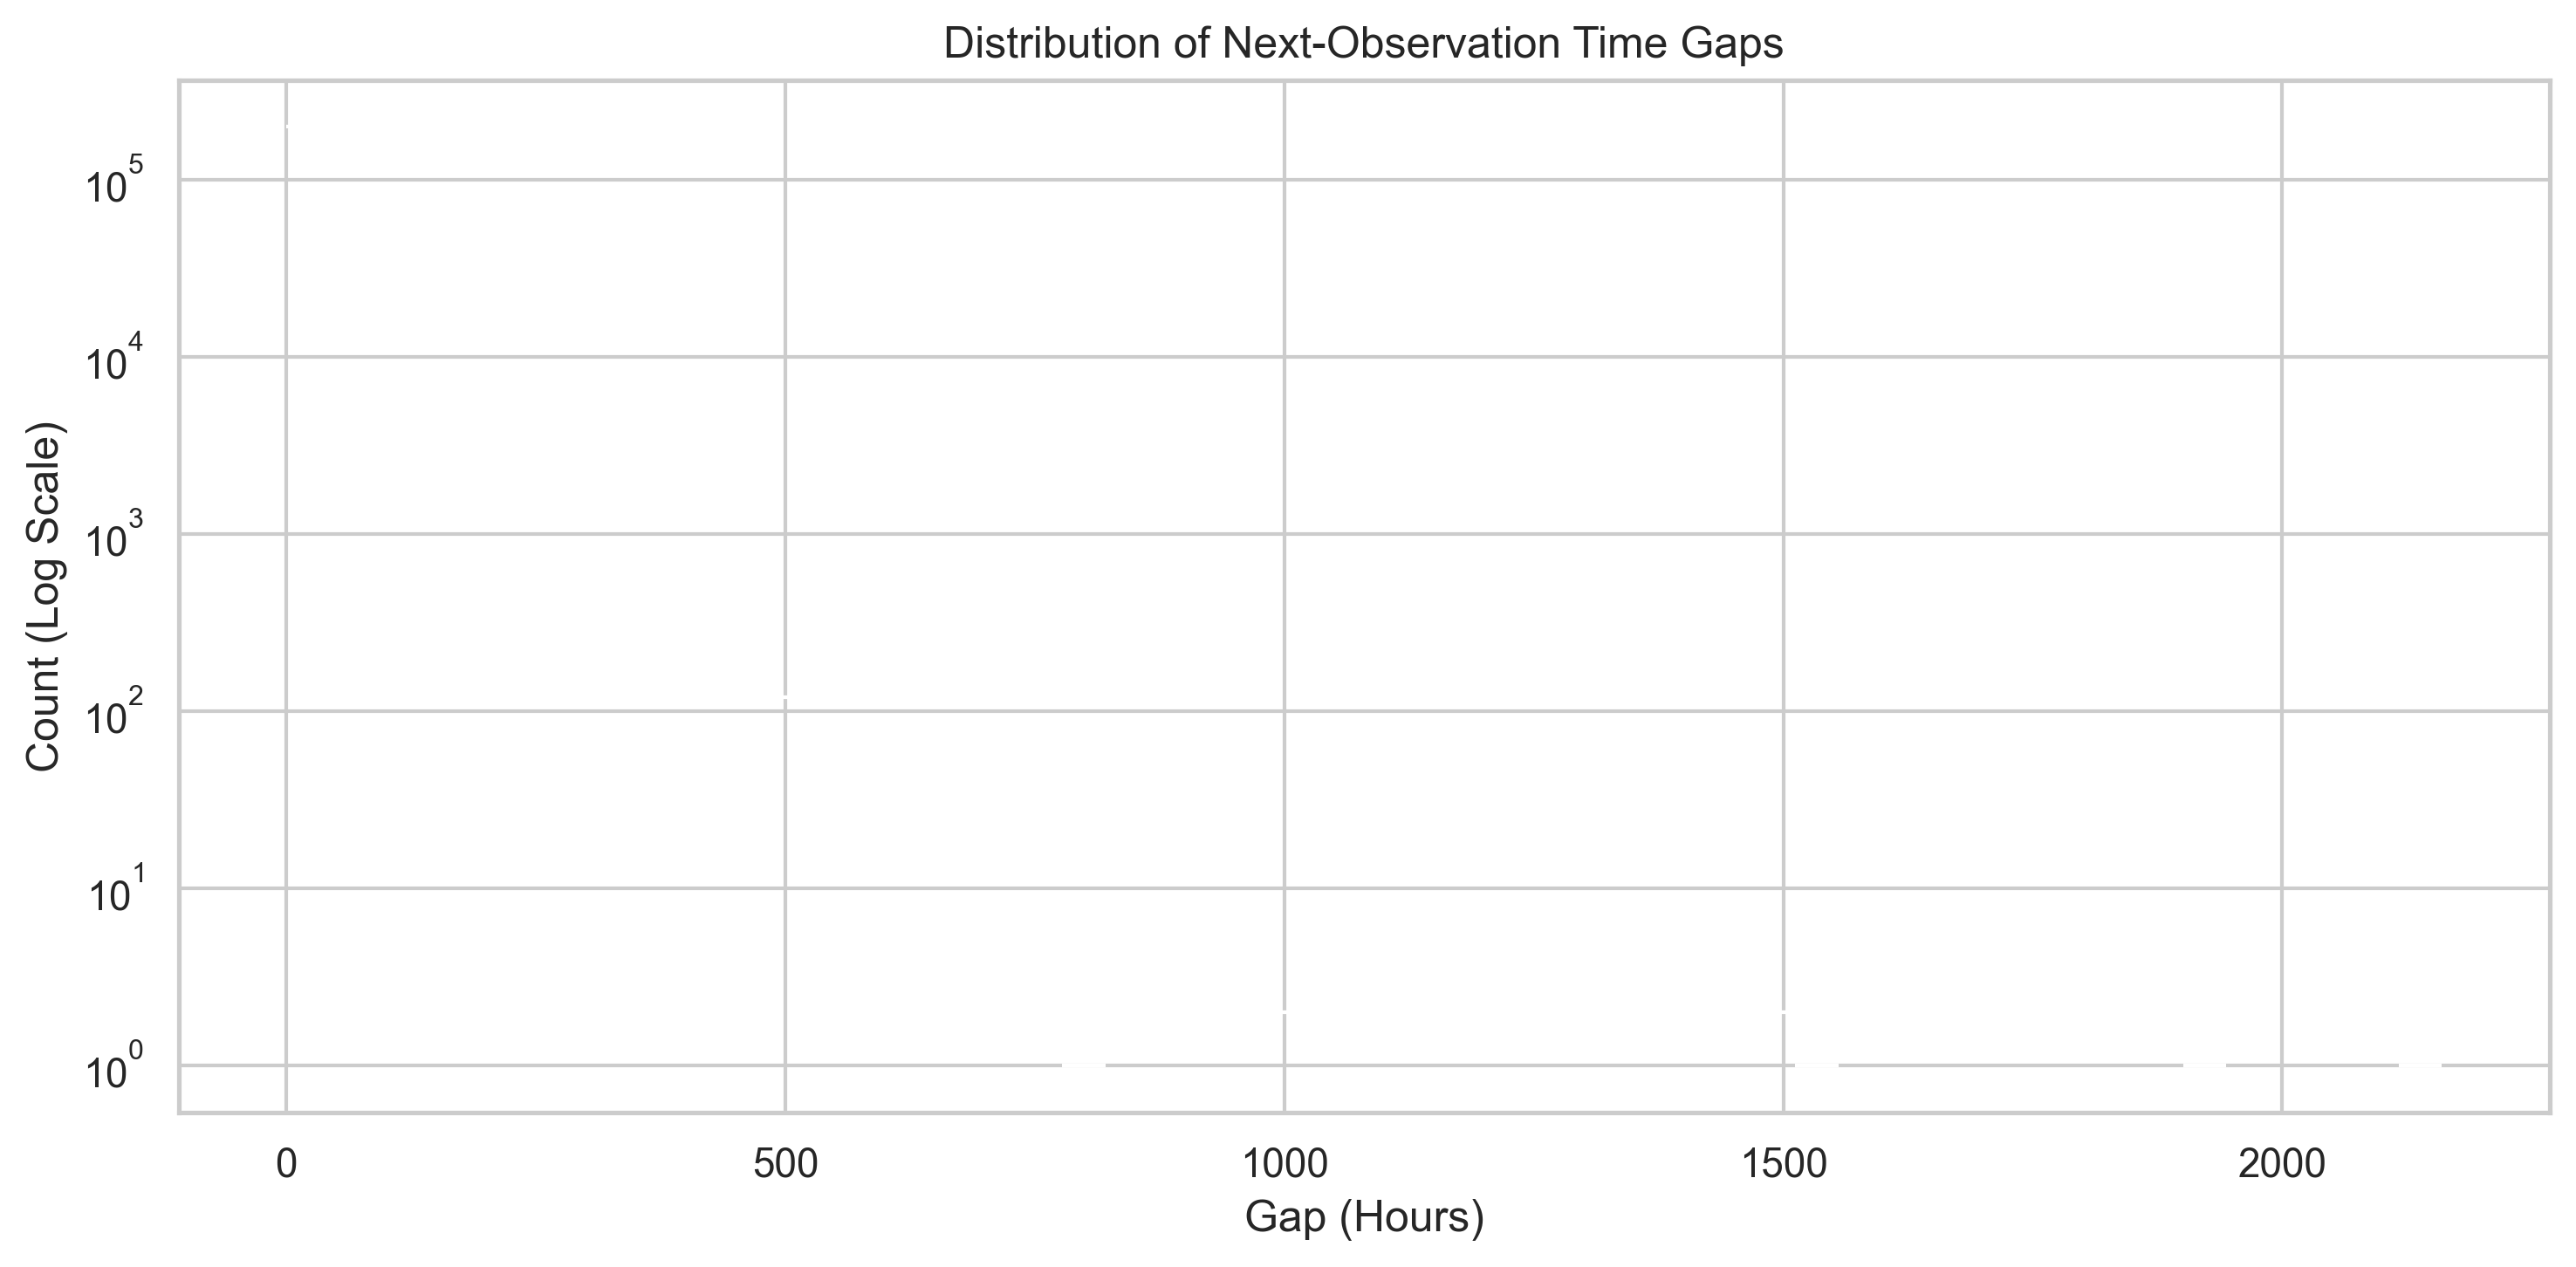

In [6]:
data_path = PROJECT_ROOT / "data" / "features" / "maharashtra" / "maharashtra_weather_ml_ready.parquet"
df_raw = pd.read_parquet(data_path)

# Calculate target gap correctly
df_raw["obs_dt"] = pd.to_datetime(df_raw["observation_timestamp_utc"], utc=True)
df_raw["target_dt"] = pd.to_datetime(df_raw["target_timestamp_utc"], utc=True)
df_raw["target_gap_hours"] = (df_raw["target_dt"] - df_raw["obs_dt"]).dt.total_seconds() / 3600.0

total_observations = len(df_raw)
total_sites = df_raw["candidate_site_id"].nunique()

print(f"Number of Maharashtra candidate sites: {total_sites}")
print(f"Number of valid observations: {total_observations}")
print(f"Date range: {df_raw['obs_dt'].min().strftime('%Y-%m-%d')} to {df_raw['obs_dt'].max().strftime('%Y-%m-%d')}")
print(f"Water-level unit: meters (depth to water level)")

# Target gap statistics
gap_stats = df_raw["target_gap_hours"].describe(percentiles=[.25, .5, .75, .90, .95])
print("\nNext-Observation Gap Statistics (Hours):")
print(gap_stats.to_frame().T)

fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(df_raw["target_gap_hours"].dropna(), bins=50, ax=ax, log_scale=(False, True))
ax.set_title("Distribution of Next-Observation Time Gaps")
ax.set_xlabel("Gap (Hours)")
ax.set_ylabel("Count (Log Scale)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "01_target_gap_distribution.png")
plt.show()


## 3. Data Quality and Evaluation Eligibility
Filtering data according to project evaluation rules.

In [7]:
# Feature engineering required for ML models
df = df_raw.sort_values(["candidate_site_id", "obs_dt"]).reset_index(drop=True)
df["lag_1"] = df.groupby("candidate_site_id")["water_level_raw"].shift(1)
df["hour"] = df["obs_dt"].dt.hour

# Drop rows that cannot be used for target training
df_clean = df.dropna(subset=["lag_1", "target_water_level"]).copy()

used_for_eval = len(df_clean)
excluded = total_observations - used_for_eval

quality_summary = pd.DataFrame([
    {"Metric": "Total observations", "Count": total_observations},
    {"Metric": "Excluded (Missing lag or target)", "Count": excluded},
    {"Metric": "Used for model evaluation", "Count": used_for_eval}
])
quality_summary.to_csv(TABLES_DIR / "data_quality_summary.csv", index=False)
display(quality_summary)


,Metric,Count
0,Total observations,210468
1,Excluded (Missing lag or target),1011
2,Used for model evaluation,209457


## 4. Target Definition
The target $X_{t+1}$ is the next valid observation for the given candidate site. Example subset below:

In [8]:
target_sample = df_clean[["candidate_site_id", "obs_dt", "water_level_raw", "target_dt", "target_water_level", "target_gap_hours"]].head(5)
target_sample.to_csv(TABLES_DIR / "target_definition_sample.csv", index=False)
display(target_sample)


,candidate_site_id,obs_dt,water_level_raw,target_dt,target_water_level,target_gap_hours
1,MH_AALEGAON,2026-01-01 00:30:00+00:00,-6.025,2026-01-01 06:30:00+00:00,-6.420,6.0
2,MH_AALEGAON,2026-01-01 06:30:00+00:00,-6.420,2026-01-01 12:30:00+00:00,-6.056,6.0
3,MH_AALEGAON,2026-01-01 12:30:00+00:00,-6.056,2026-01-01 18:30:00+00:00,-6.837,6.0
4,MH_AALEGAON,2026-01-01 18:30:00+00:00,-6.837,2026-01-02 00:30:00+00:00,-6.954,6.0
5,MH_AALEGAON,2026-01-02 00:30:00+00:00,-6.954,2026-01-02 06:30:00+00:00,-6.815,6.0


## 5. Chronological / Target-Isolated Split
Applying strict chronological split to avoid leakage.

,Split,Start,End,Observations,Sites
0,Train,2026-01-01 00:30:00+00:00,2026-04-05 00:30:00+00:00,146028,998
1,Validation,2026-04-05 12:30:00+00:00,2026-04-27 00:30:00+00:00,30406,966
2,Test,2026-04-27 12:30:00+00:00,2026-05-29 12:30:00+00:00,31272,784


PASS: Train targets do not cross into validation/test.
PASS: Validation targets do not cross into test.


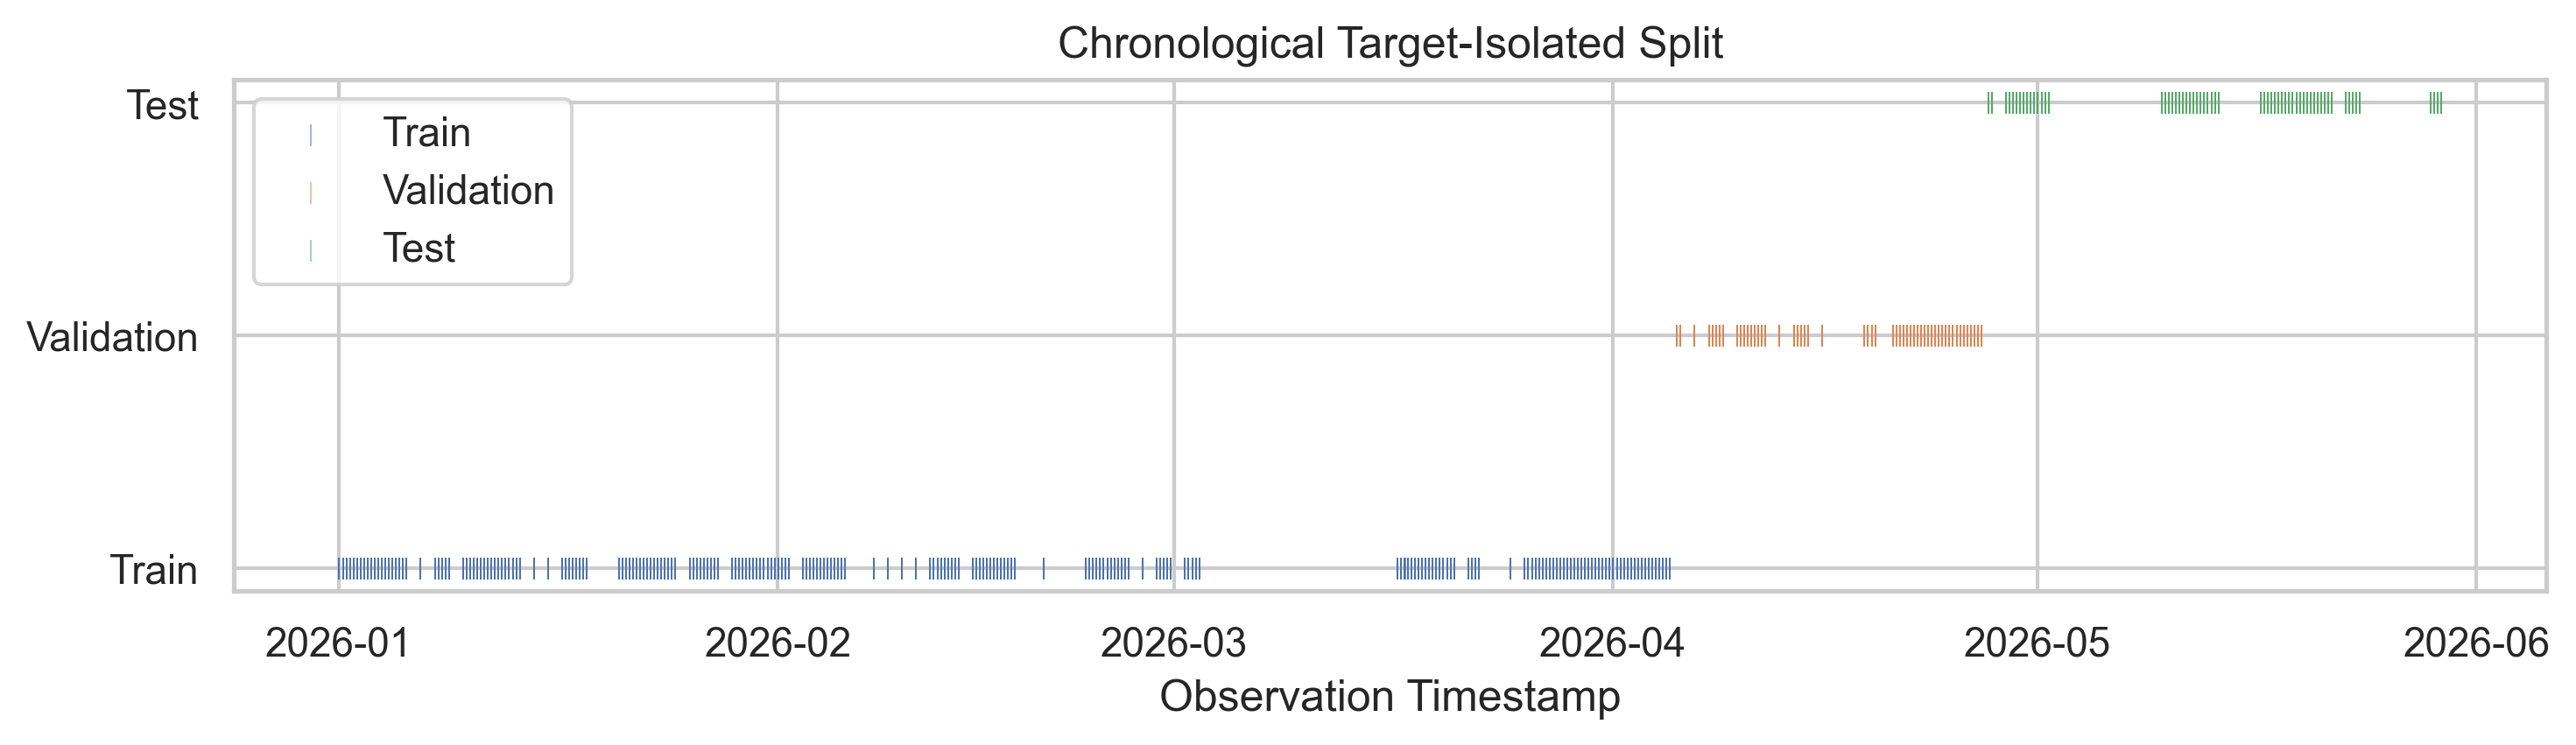

In [9]:
t_train = pd.to_datetime("2026-04-05 06:30:00", utc=True)
t_val = pd.to_datetime("2026-04-27 06:30:00", utc=True)

# Strict isolation
train_mask = (df_clean["obs_dt"] <= t_train) & (df_clean["target_dt"] <= t_train)
val_mask = (df_clean["obs_dt"] > t_train) & (df_clean["obs_dt"] <= t_val) & (df_clean["target_dt"] <= t_val)
test_mask = (df_clean["obs_dt"] > t_val)

train_df = df_clean[train_mask].copy()
val_df = df_clean[val_mask].copy()
test_df = df_clean[test_mask].copy()

split_stats = pd.DataFrame([
    {"Split": "Train", "Start": train_df["obs_dt"].min(), "End": train_df["obs_dt"].max(), "Observations": len(train_df), "Sites": train_df["candidate_site_id"].nunique()},
    {"Split": "Validation", "Start": val_df["obs_dt"].min(), "End": val_df["obs_dt"].max(), "Observations": len(val_df), "Sites": val_df["candidate_site_id"].nunique()},
    {"Split": "Test", "Start": test_df["obs_dt"].min(), "End": test_df["obs_dt"].max(), "Observations": len(test_df), "Sites": test_df["candidate_site_id"].nunique()}
])
split_stats.to_csv(TABLES_DIR / "split_statistics.csv", index=False)
display(split_stats)

assert_check(train_df["target_dt"].max() <= t_train, "Train targets do not cross into validation/test.")
assert_check(val_df["target_dt"].max() <= t_val, "Validation targets do not cross into test.")

fig, ax = plt.subplots(figsize=(10, 3))
sns.scatterplot(x=train_df["obs_dt"], y=np.zeros(len(train_df)), marker="|", alpha=0.5, label="Train")
sns.scatterplot(x=val_df["obs_dt"], y=np.ones(len(val_df)), marker="|", alpha=0.5, label="Validation")
sns.scatterplot(x=test_df["obs_dt"], y=np.ones(len(test_df))*2, marker="|", alpha=0.5, label="Test")
ax.set_yticks([0,1,2])
ax.set_yticklabels(["Train", "Validation", "Test"])
ax.set_xlabel("Observation Timestamp")
ax.set_title("Chronological Target-Isolated Split")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "02_temporal_split.png")
plt.show()


## 6. Model Inventory
Comparing Persistence (production baseline) vs ML (experimental) models.

In [10]:
features = [
    "water_level_raw", "lag_1", "hour",
    "precip_sum_24h", "precip_sum_3d", "precip_sum_7d", "precip_sum_14d", "precip_sum_30d",
    "et0_sum_24h", "et0_sum_7d", "et0_sum_30d"
]

inventory = pd.DataFrame([
    {"Model": "Persistence", "Type": "Baseline", "Status": "Production", "Inputs": "Current Observation", "Target": "Next Observation"},
    {"Model": "HistGradientBoosting", "Type": "ML", "Status": "Experimental", "Inputs": "GW + Weather Lags", "Target": "Next Observation"},
    {"Model": "XGBoost", "Type": "ML", "Status": "Experimental", "Inputs": "GW + Weather Lags", "Target": "Next Observation"}
])
display(inventory)

X_train = train_df[features]
y_train = train_df["target_water_level"]
X_test = test_df[features]
y_test = test_df["target_water_level"]

# 1. Persistence
test_df["pred_Persistence"] = test_df["water_level_raw"]

# 2. HistGradientBoosting
model_hgb = HistGradientBoostingRegressor(random_state=42)
model_hgb.fit(X_train, y_train)
test_df["pred_HGB"] = model_hgb.predict(X_test)

# 3. XGBoost
model_xgb = XGBRegressor(random_state=42, n_estimators=100, max_depth=6, learning_rate=0.1)
model_xgb.fit(X_train, y_train)
test_df["pred_XGBoost"] = model_xgb.predict(X_test)

models = ["Persistence", "HGB", "XGBoost"]

assert_check(not test_df["pred_Persistence"].isna().any(), "No NaNs in Persistence predictions.")
assert_check(not test_df["pred_HGB"].isna().any(), "No NaNs in HGB predictions.")
assert_check(not test_df["pred_XGBoost"].isna().any(), "No NaNs in XGBoost predictions.")


,Model,Type,Status,Inputs,Target
0,Persistence,Baseline,Production,Current Observation,Next Observation
1,HistGradientBoosting,ML,Experimental,GW + Weather Lags,Next Observation
2,XGBoost,ML,Experimental,GW + Weather Lags,Next Observation


PASS: No NaNs in Persistence predictions.
PASS: No NaNs in HGB predictions.
PASS: No NaNs in XGBoost predictions.


## 7. Overall Performance Metrics

In [11]:
def calc_metrics(y_true, y_pred, model_name):
    return {
        "Model": model_name,
        "MAE (m)": mean_absolute_error(y_true, y_pred),
        "MedAE (m)": median_absolute_error(y_true, y_pred),
        "RMSE (m)": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R²": r2_score(y_true, y_pred),
        "N": len(y_true)
    }

metrics_list = []
for m in models:
    metrics_list.append(calc_metrics(test_df["target_water_level"], test_df[f"pred_{m}"], m))

overall_metrics = pd.DataFrame(metrics_list).sort_values("MAE (m)")
overall_metrics.to_csv(TABLES_DIR / "overall_metrics.csv", index=False)
display(overall_metrics)


,Model,MAE (m),MedAE (m),RMSE (m),R²,N
0,Persistence,0.348351,0.020000,4.246217,0.997044,31272
2,XGBoost,3.910332,0.179070,74.510377,0.089755,31272
1,HGB,3.969415,0.097577,73.494669,0.114402,31272


## 8. Error Distribution

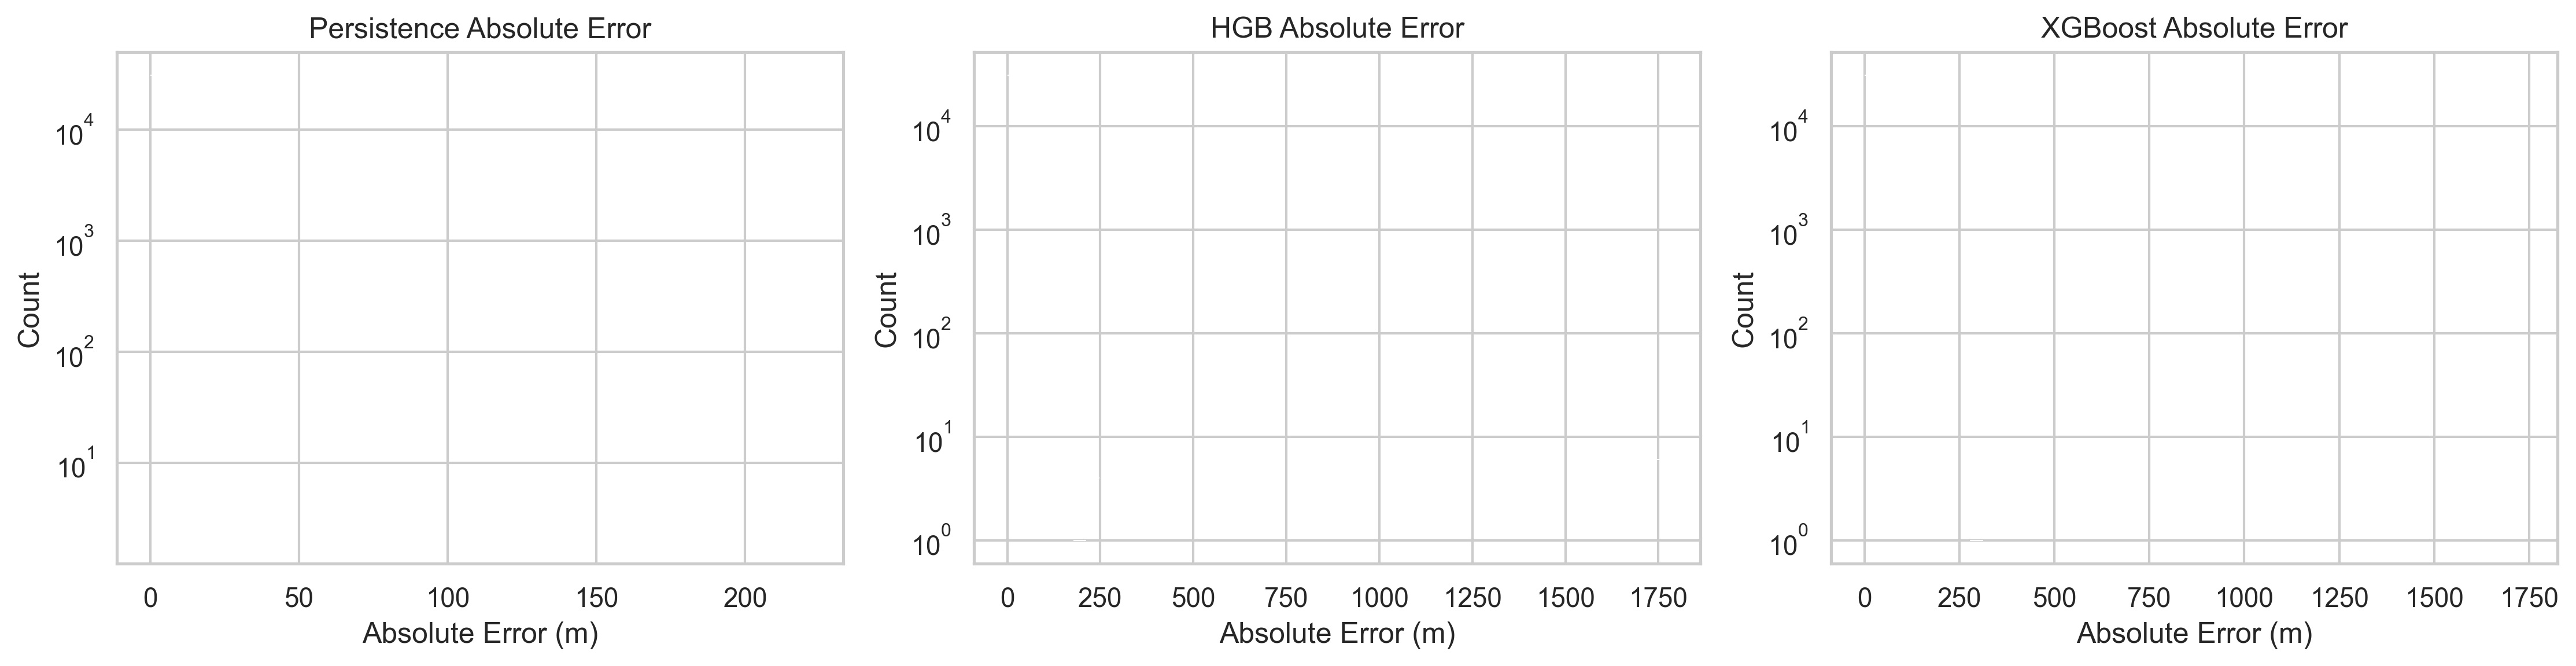

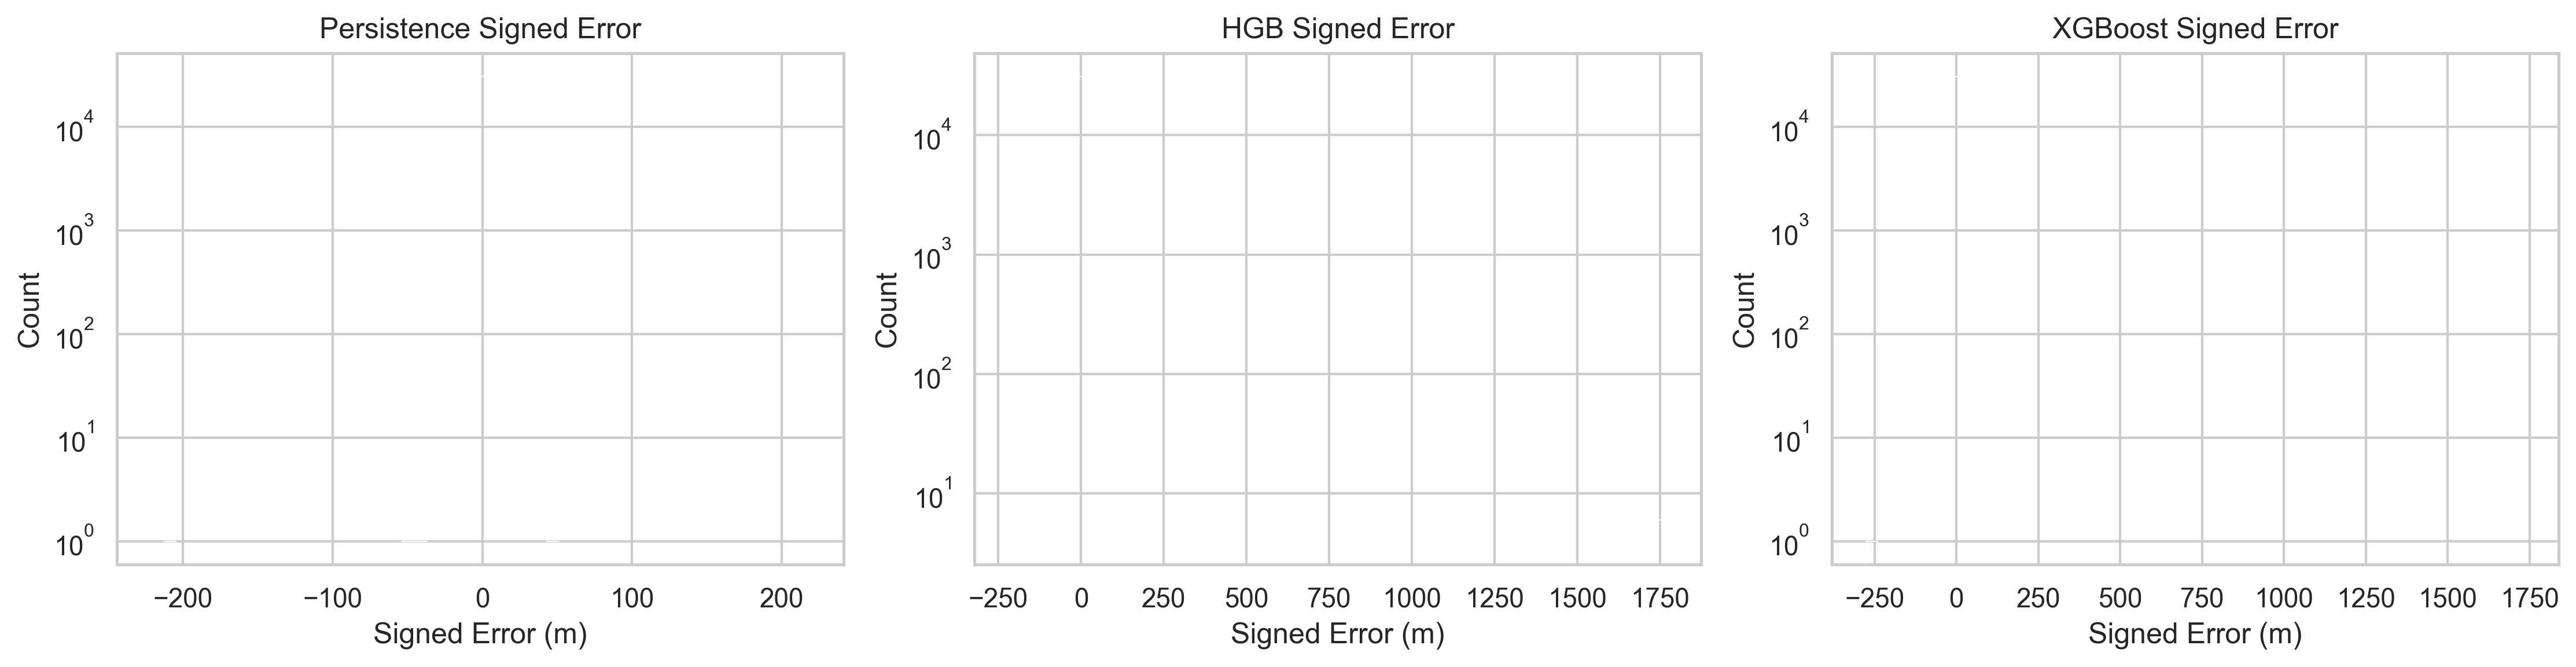

In [12]:
for m in models:
    test_df[f"error_{m}"] = test_df[f"pred_{m}"] - test_df["target_water_level"]
    test_df[f"abs_error_{m}"] = test_df[f"error_{m}"].abs()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for i, m in enumerate(models):
    sns.histplot(test_df[f"abs_error_{m}"], bins=50, ax=axes[i], log_scale=(False, True))
    axes[i].set_title(f"{m} Absolute Error")
    axes[i].set_xlabel("Absolute Error (m)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "04_absolute_error_distribution.png")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for i, m in enumerate(models):
    sns.histplot(test_df[f"error_{m}"], bins=50, ax=axes[i], log_scale=(False, True))
    axes[i].set_title(f"{m} Signed Error")
    axes[i].set_xlabel("Signed Error (m)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "05_residual_distribution.png")
plt.show()


## 9. Actual vs Predicted

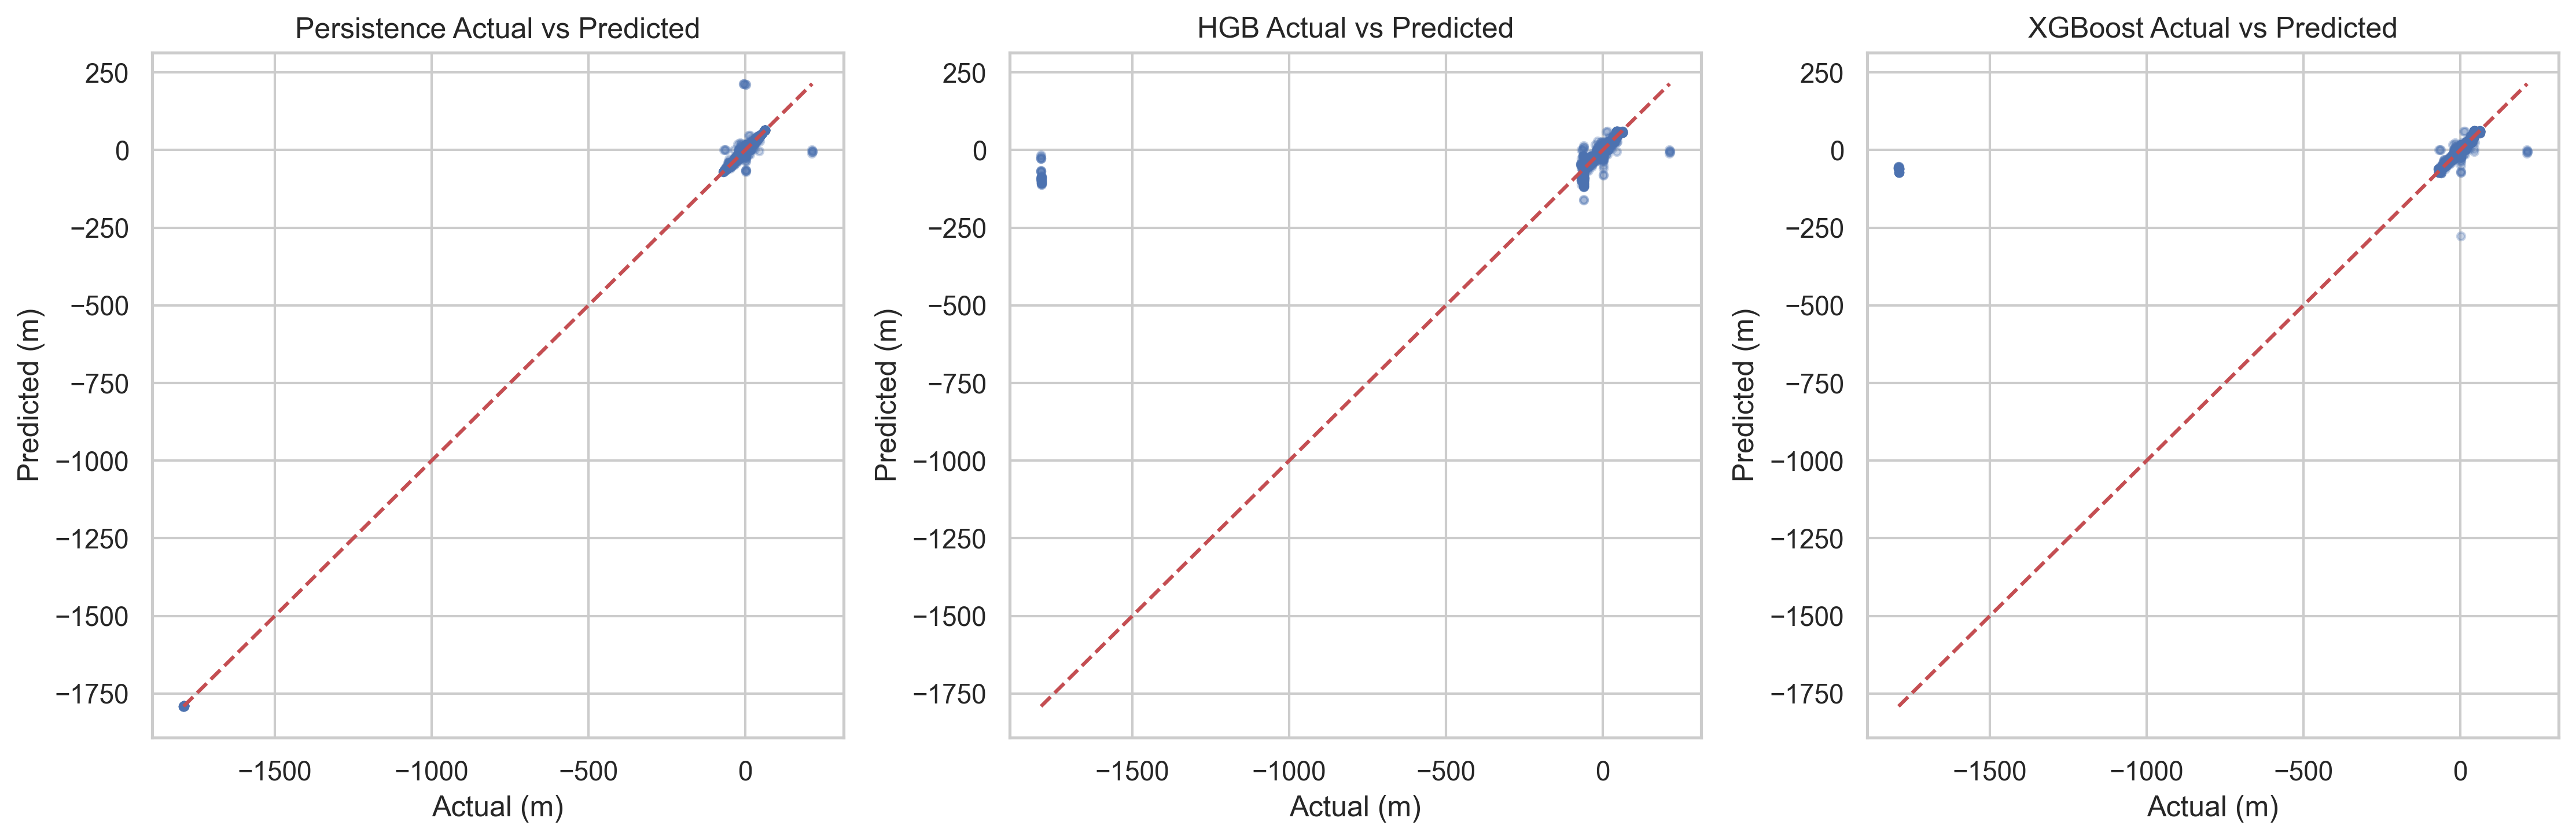

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for i, m in enumerate(models):
    ax = axes[i]
    ax.scatter(test_df["target_water_level"], test_df[f"pred_{m}"], alpha=0.3, s=10)
    min_val = min(test_df["target_water_level"].min(), test_df[f"pred_{m}"].min())
    max_val = max(test_df["target_water_level"].max(), test_df[f"pred_{m}"].max())
    ax.plot([min_val, max_val], [min_val, max_val], 'r--')
    ax.set_title(f"{m} Actual vs Predicted")
    ax.set_xlabel("Actual (m)")
    ax.set_ylabel("Predicted (m)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "06_actual_vs_predicted_all.png")
plt.show()


## 10. Prediction Error vs Actual Water Level

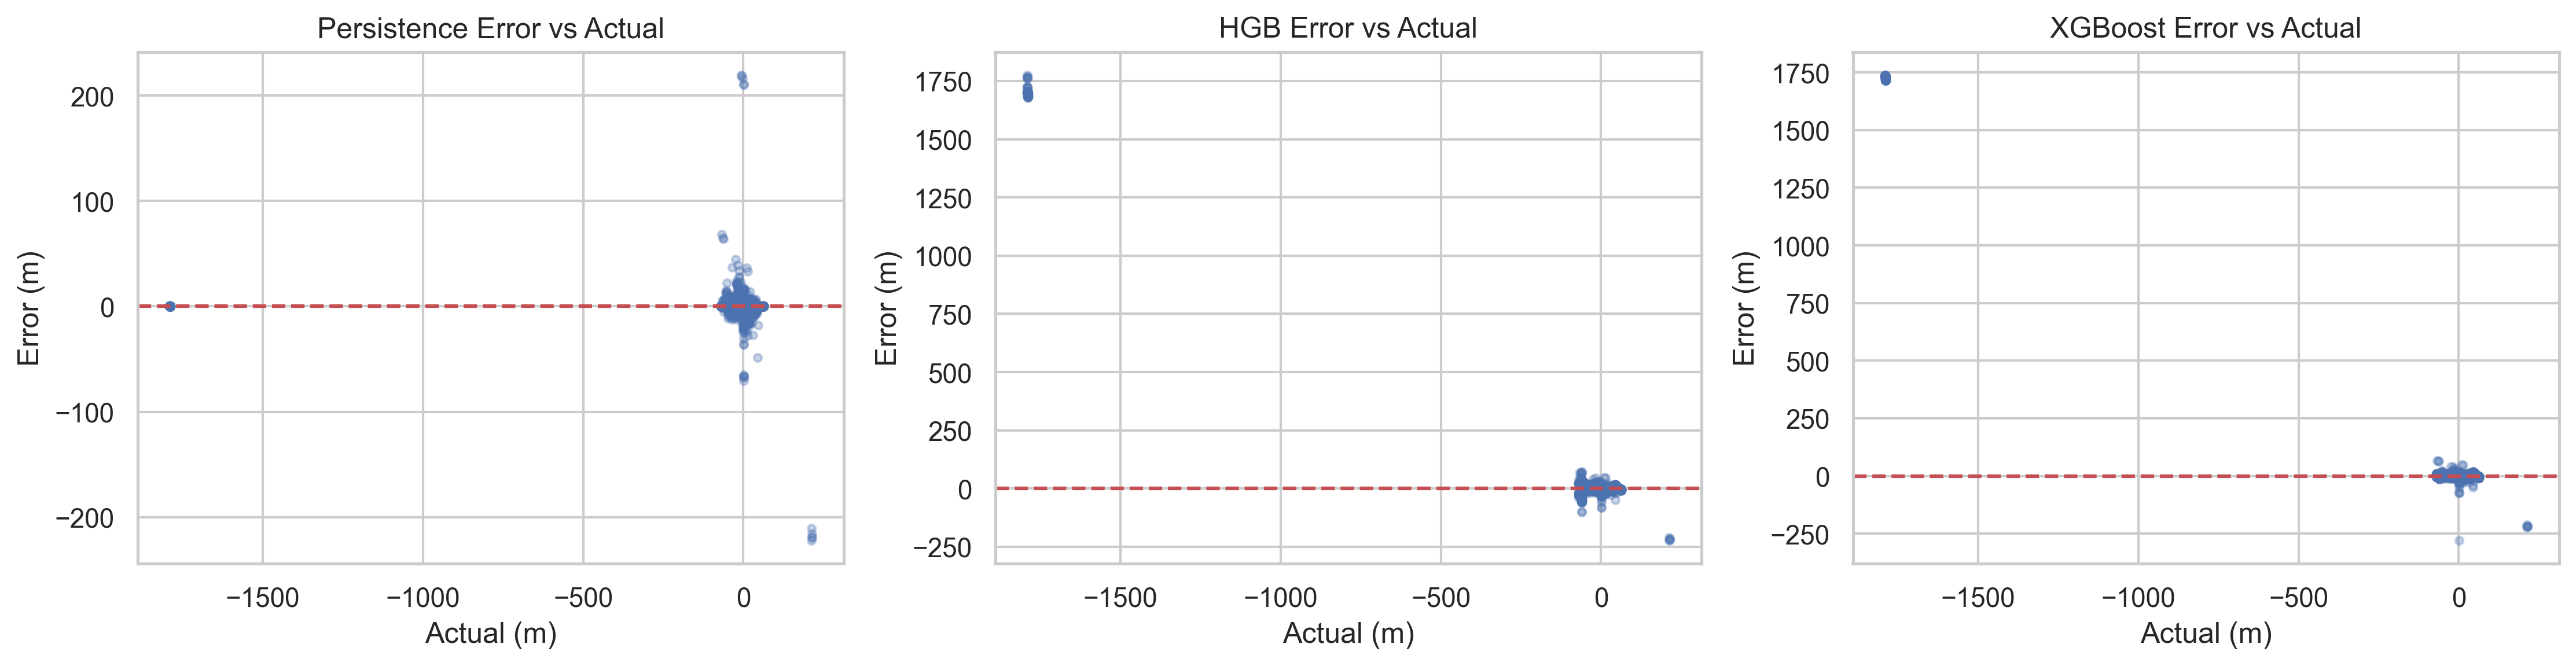

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for i, m in enumerate(models):
    ax = axes[i]
    ax.scatter(test_df["target_water_level"], test_df[f"error_{m}"], alpha=0.3, s=10)
    ax.axhline(0, color='r', linestyle='--')
    ax.set_title(f"{m} Error vs Actual")
    ax.set_xlabel("Actual (m)")
    ax.set_ylabel("Error (m)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "12_residual_vs_actual.png")
plt.show()


## 11. Time-Series Performance

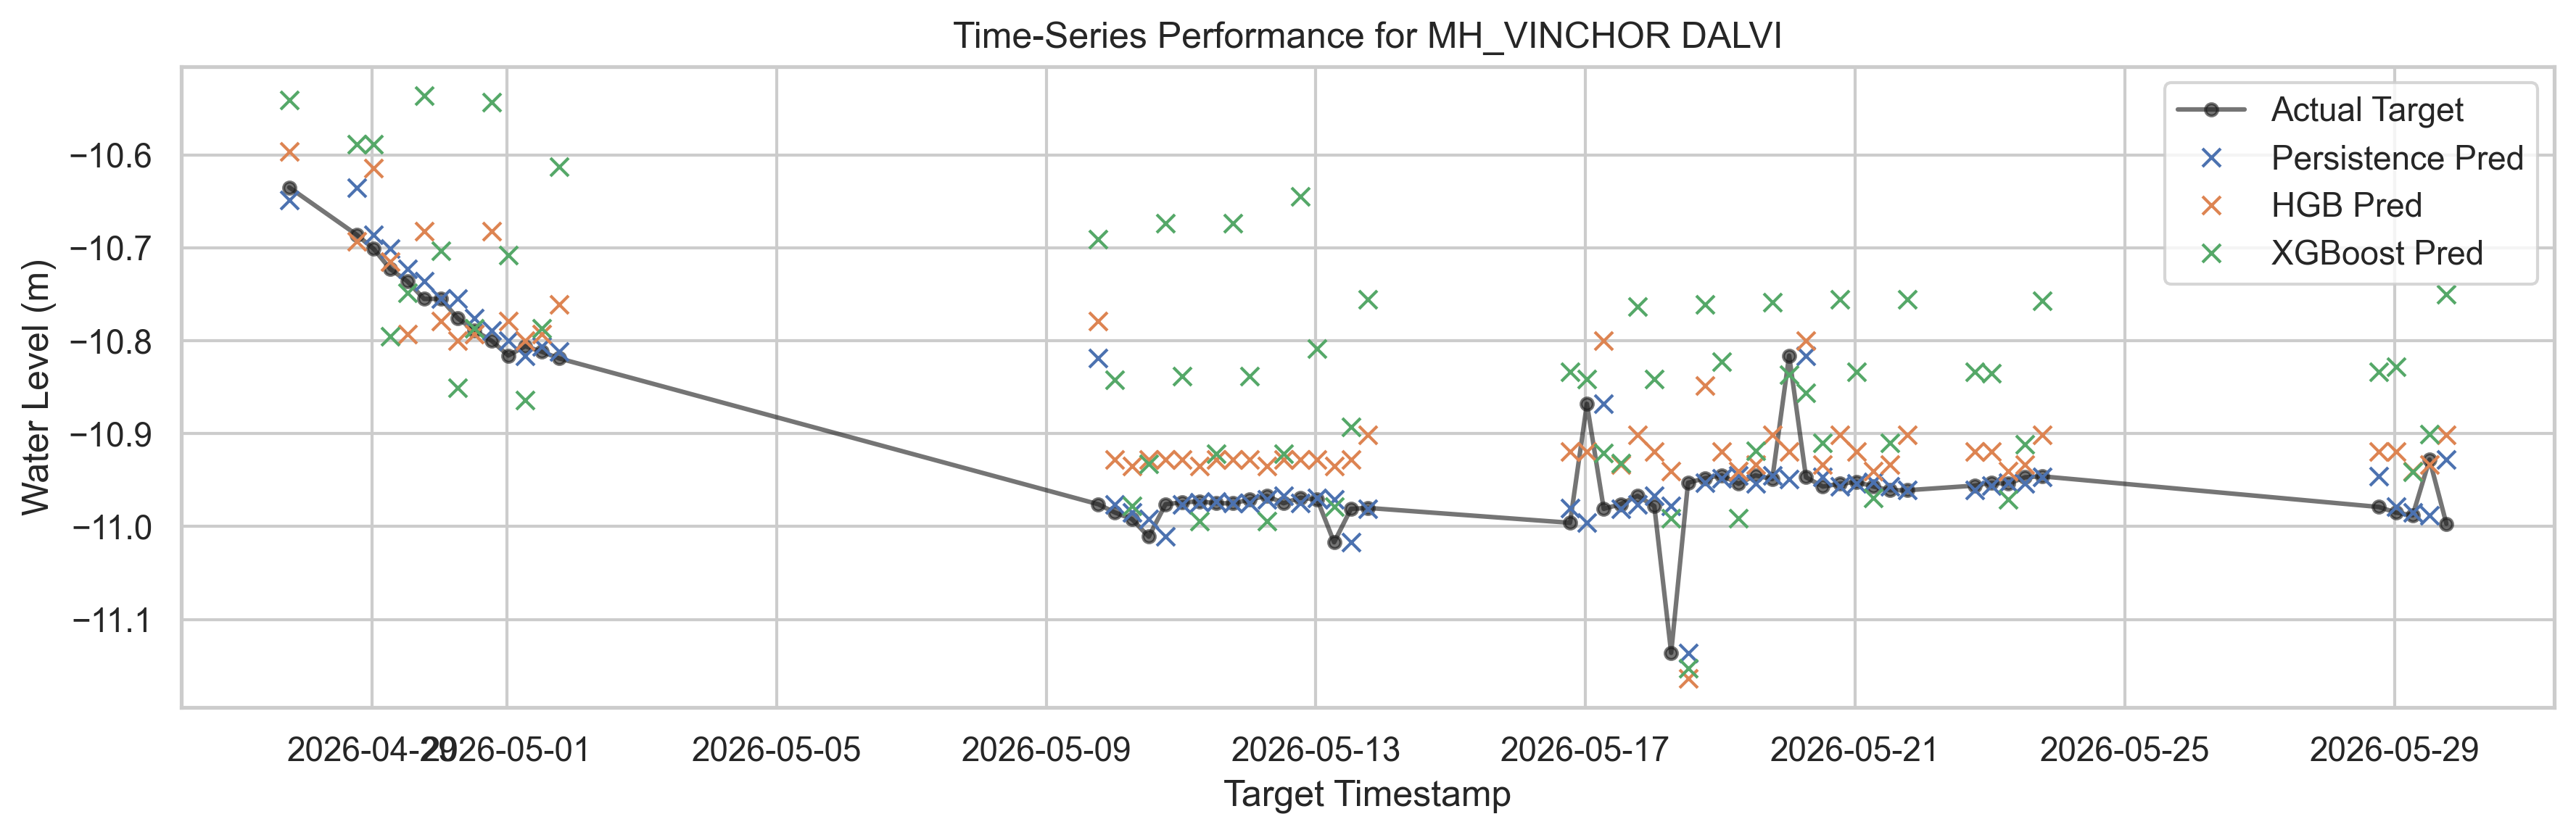

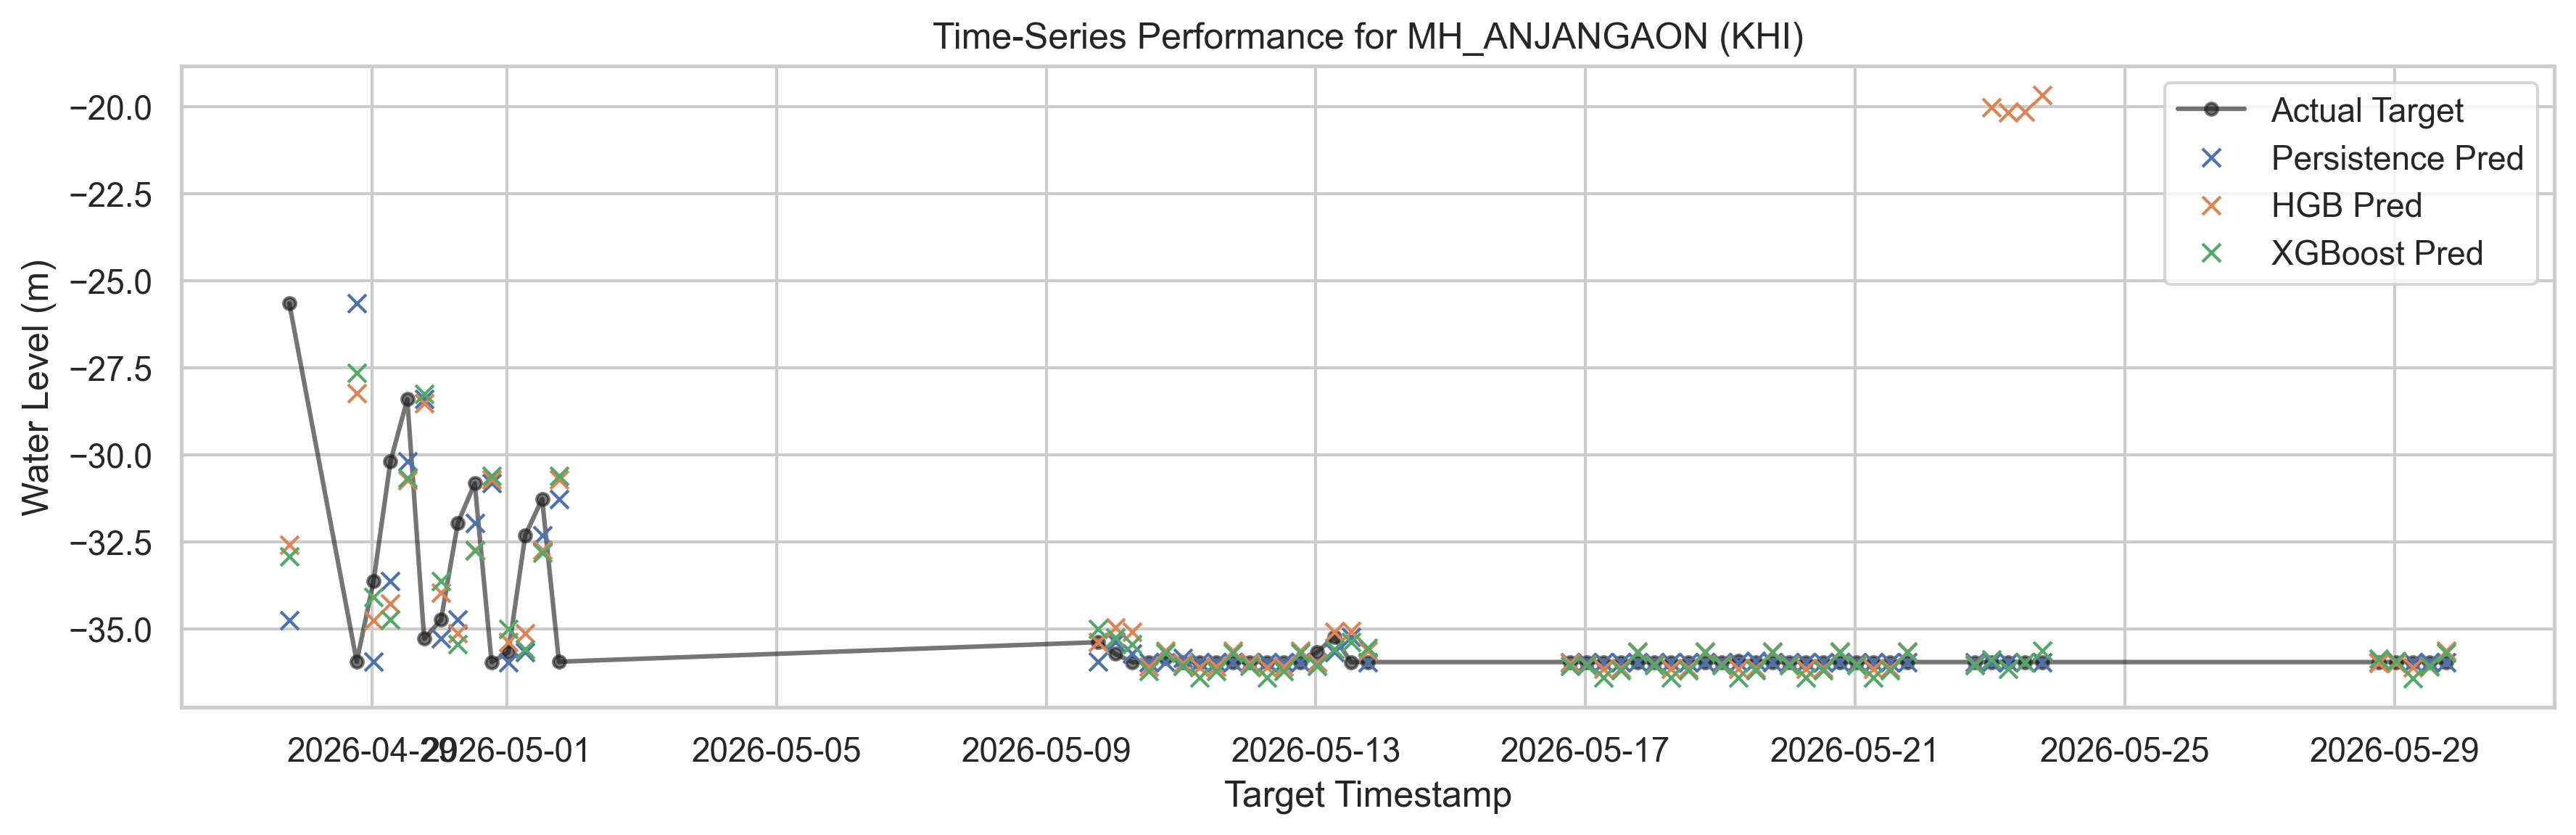

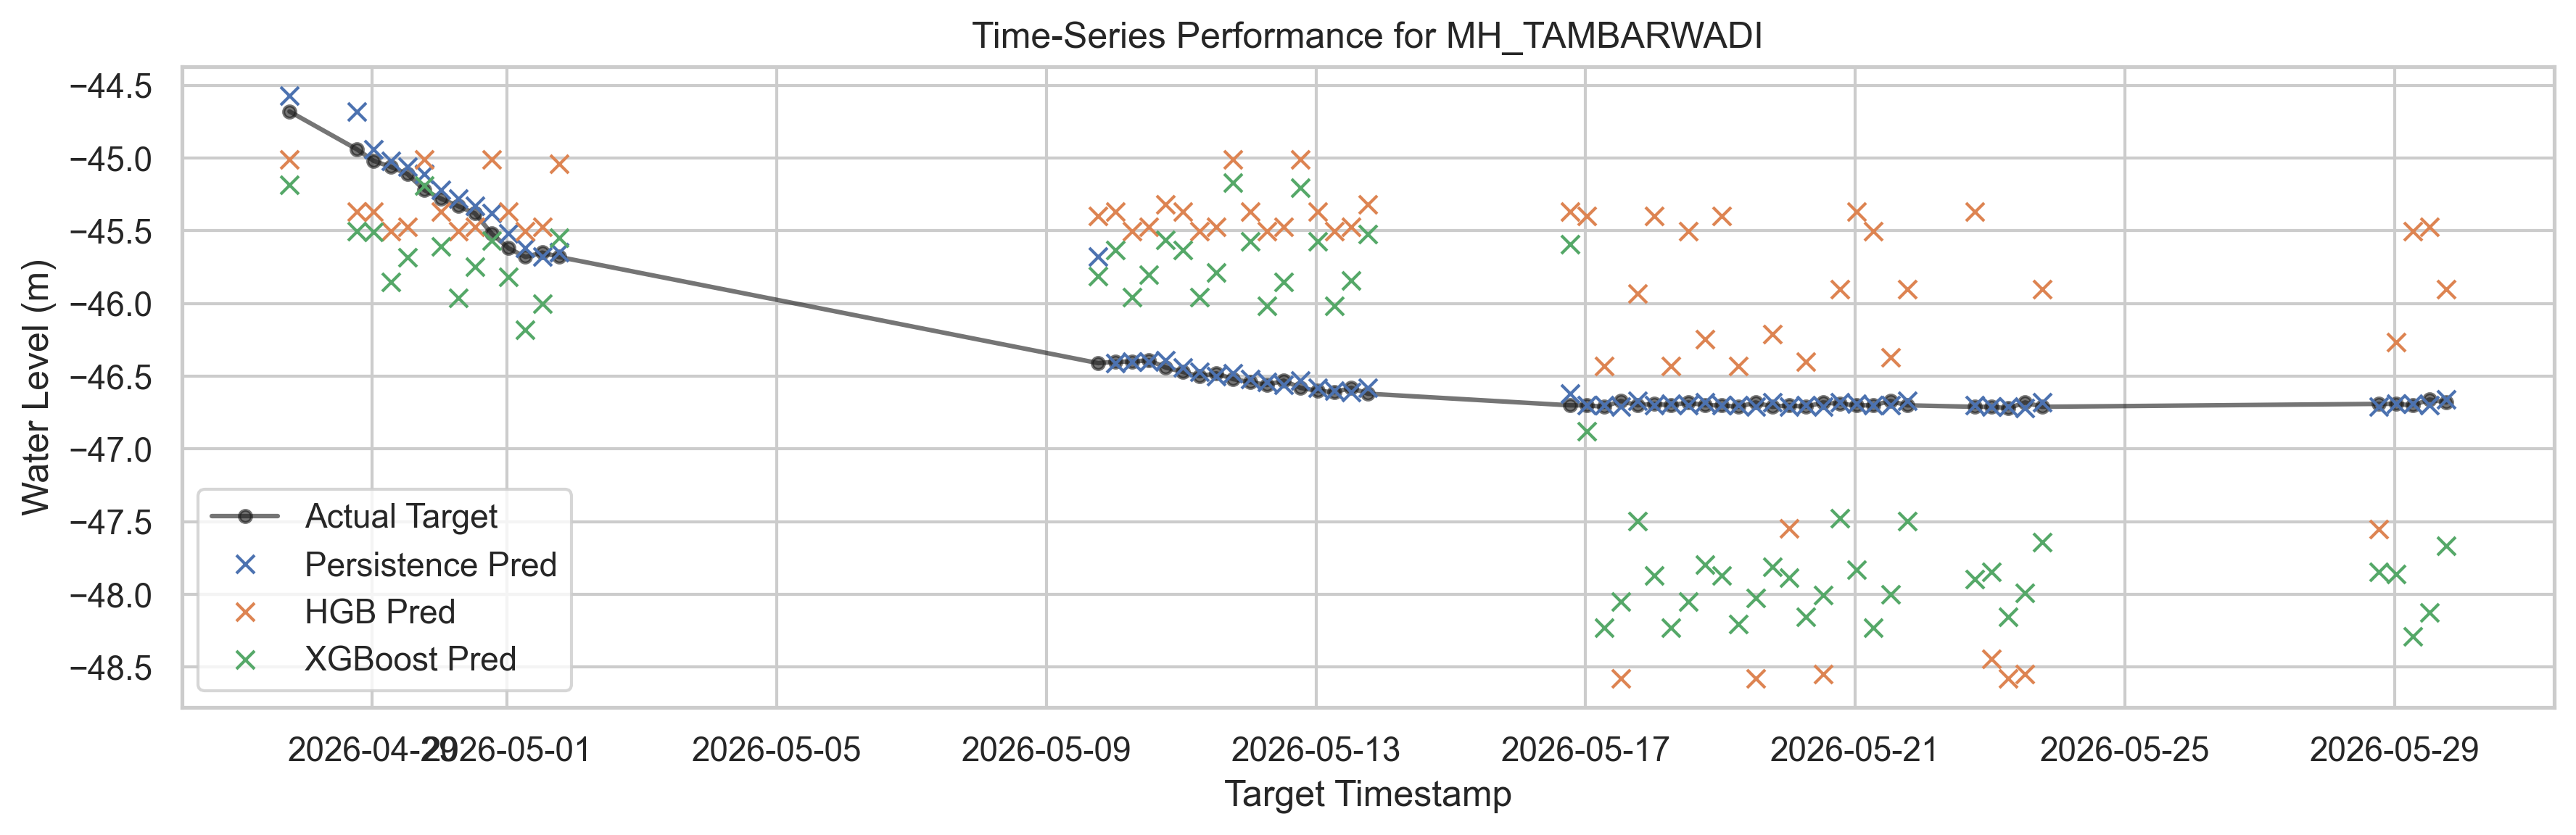

In [15]:
# Deterministic selection: Pick 3 sites with most test observations
top_sites = test_df["candidate_site_id"].value_counts().head(3).index.tolist()

for site in top_sites:
    site_df = test_df[test_df["candidate_site_id"] == site].sort_values("obs_dt")
    fig, ax = plt.subplots(figsize=(12, 4))
    
    # Plot as scatter to avoid misleading interpolation over gaps
    ax.plot(site_df["target_dt"], site_df["target_water_level"], 'ko-', label="Actual Target", markersize=4, alpha=0.6)
    for m in models:
        ax.plot(site_df["target_dt"], site_df[f"pred_{m}"], 'x', label=f"{m} Pred", markersize=6)
        
    ax.set_title(f"Time-Series Performance for {site}")
    ax.set_xlabel("Target Timestamp")
    ax.set_ylabel("Water Level (m)")
    ax.legend()
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / f"time_series_{site}.png")
    plt.show()


## 12. Performance by Forecast Gap

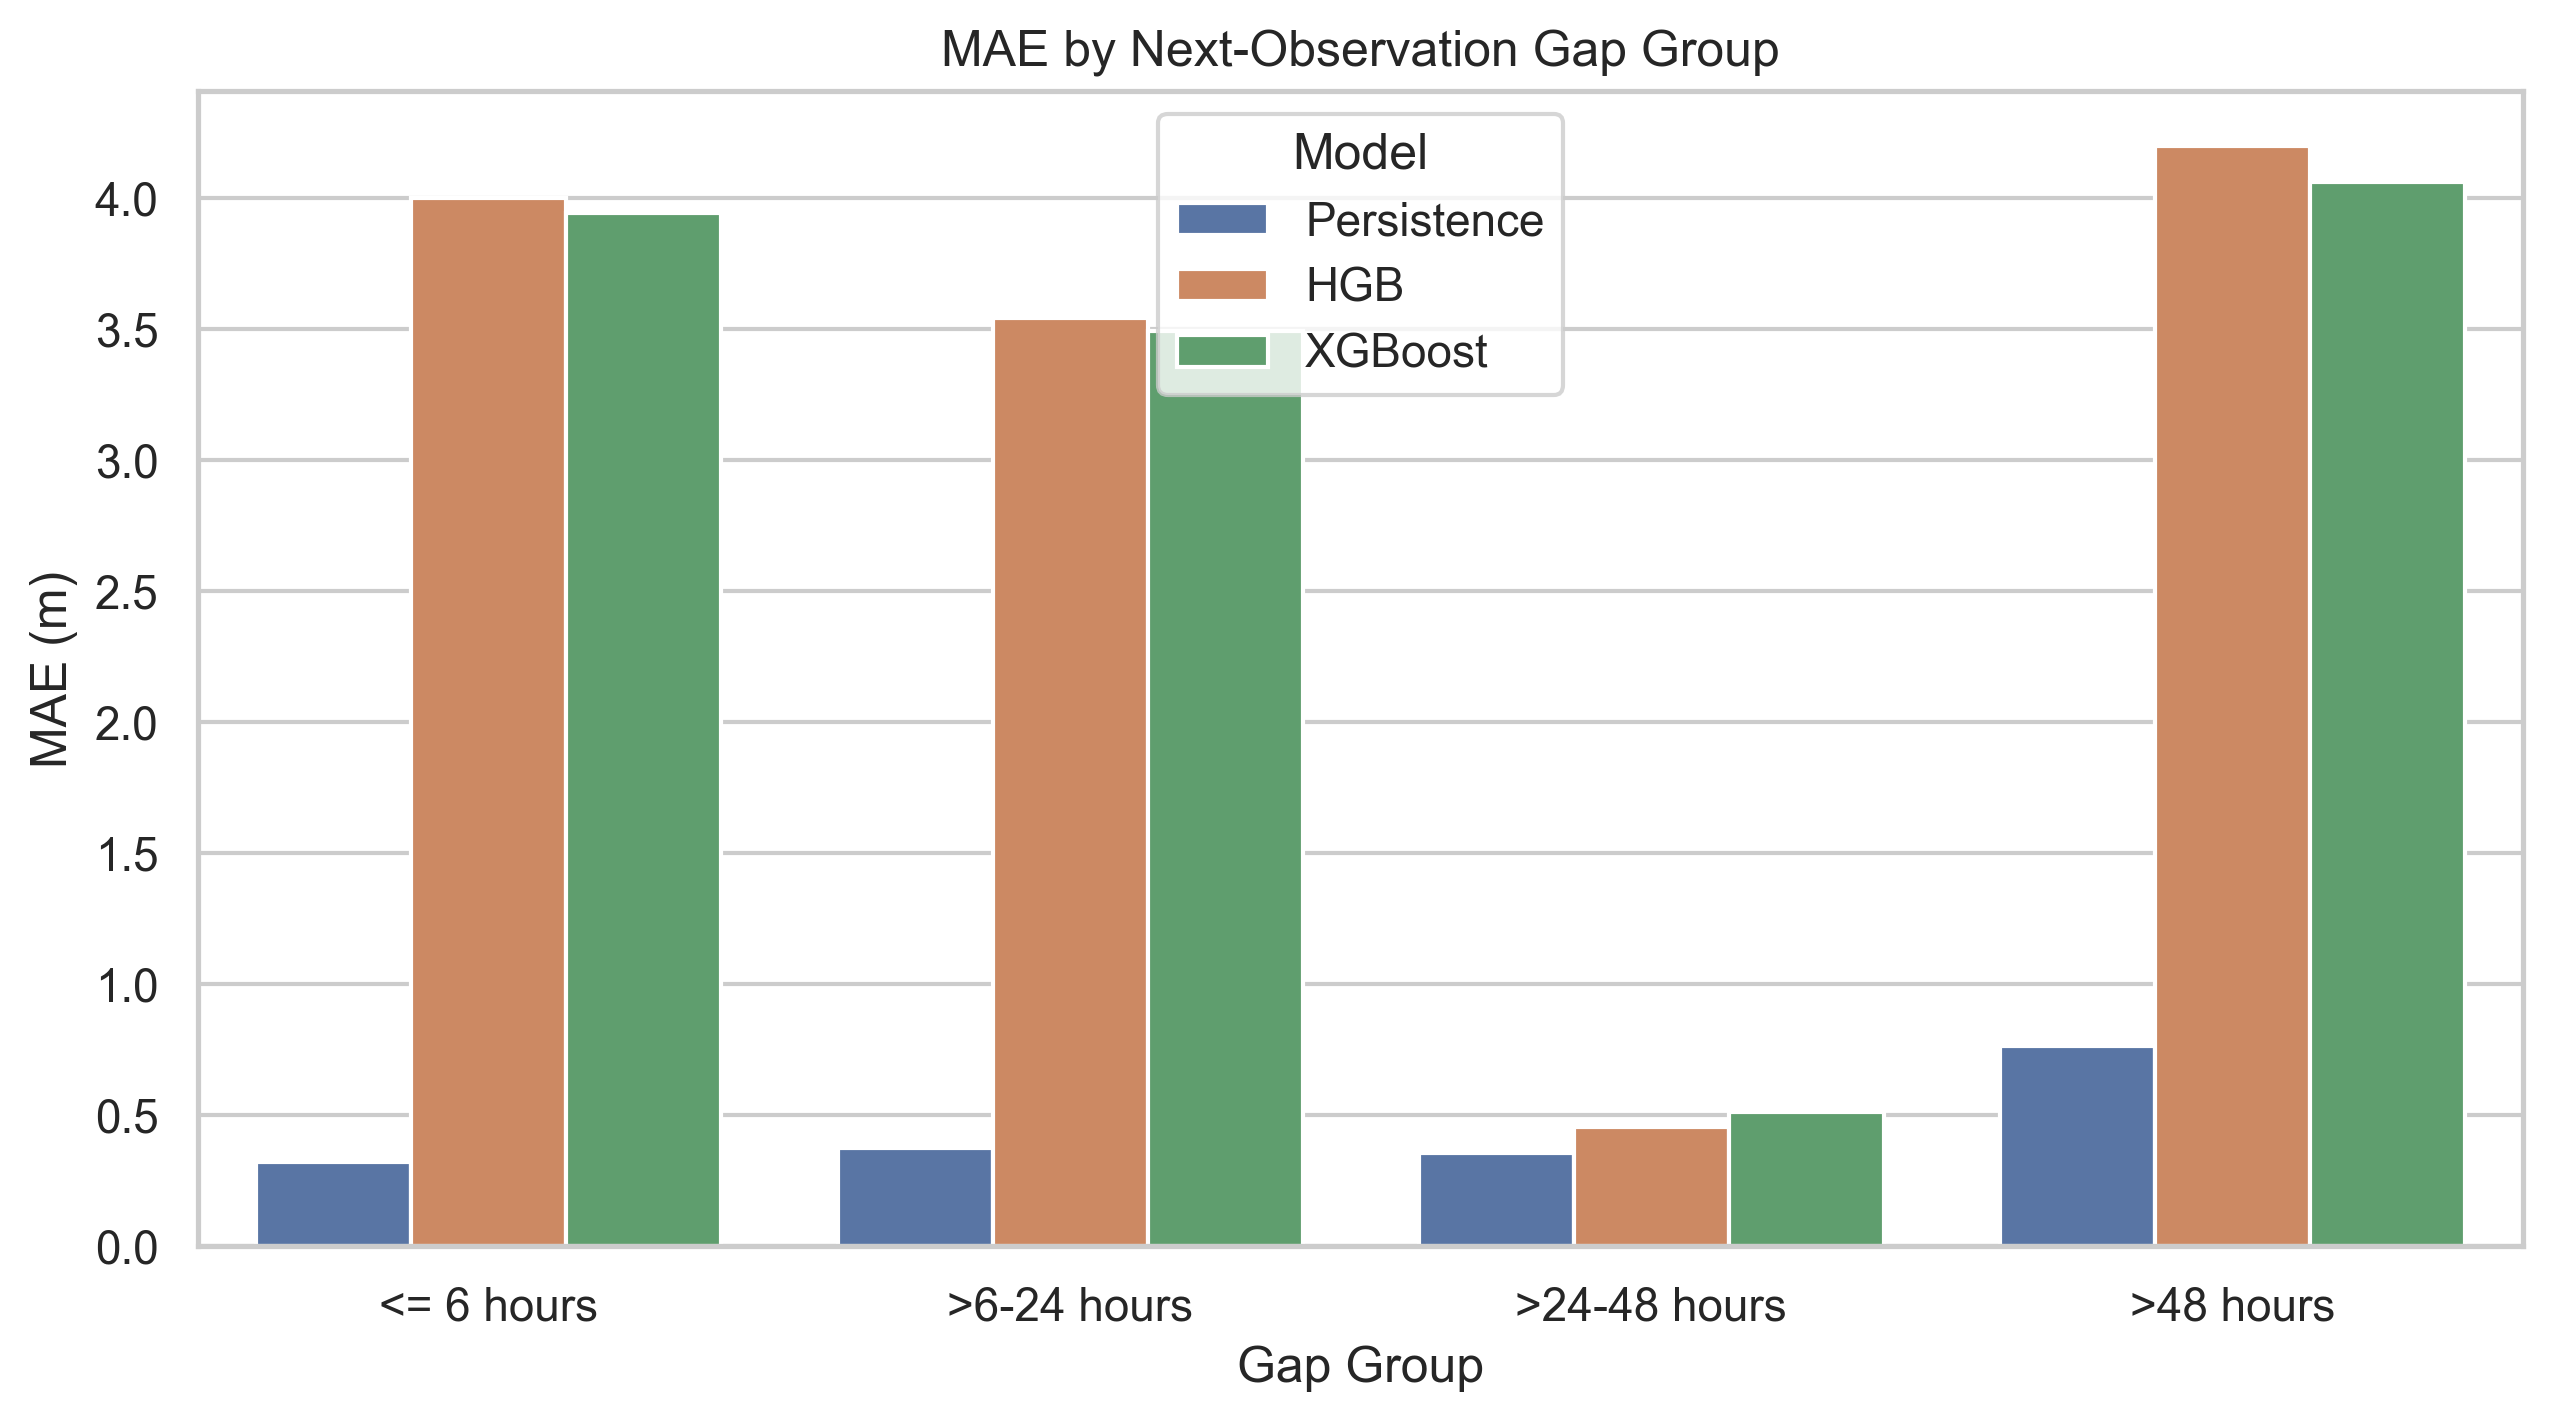

In [16]:
def gap_group(h):
    if h <= 6: return "<= 6 hours"
    if h <= 24: return ">6-24 hours"
    if h <= 48: return ">24-48 hours"
    return ">48 hours"

test_df["gap_group"] = test_df["target_gap_hours"].apply(gap_group)

gap_metrics = []
for grp in ["<= 6 hours", ">6-24 hours", ">24-48 hours", ">48 hours"]:
    grp_df = test_df[test_df["gap_group"] == grp]
    if len(grp_df) == 0: continue
    for m in models:
        res = calc_metrics(grp_df["target_water_level"], grp_df[f"pred_{m}"], m)
        res["Gap Group"] = grp
        gap_metrics.append(res)
        
gap_df = pd.DataFrame(gap_metrics)
gap_df.to_csv(TABLES_DIR / "gap_group_metrics.csv", index=False)

plt.figure(figsize=(10, 5))
sns.barplot(data=gap_df, x="Gap Group", y="MAE (m)", hue="Model")
plt.title("MAE by Next-Observation Gap Group")
plt.savefig(FIGURES_DIR / "09_gap_group_performance.png")
plt.show()


## 13. Performance by Site

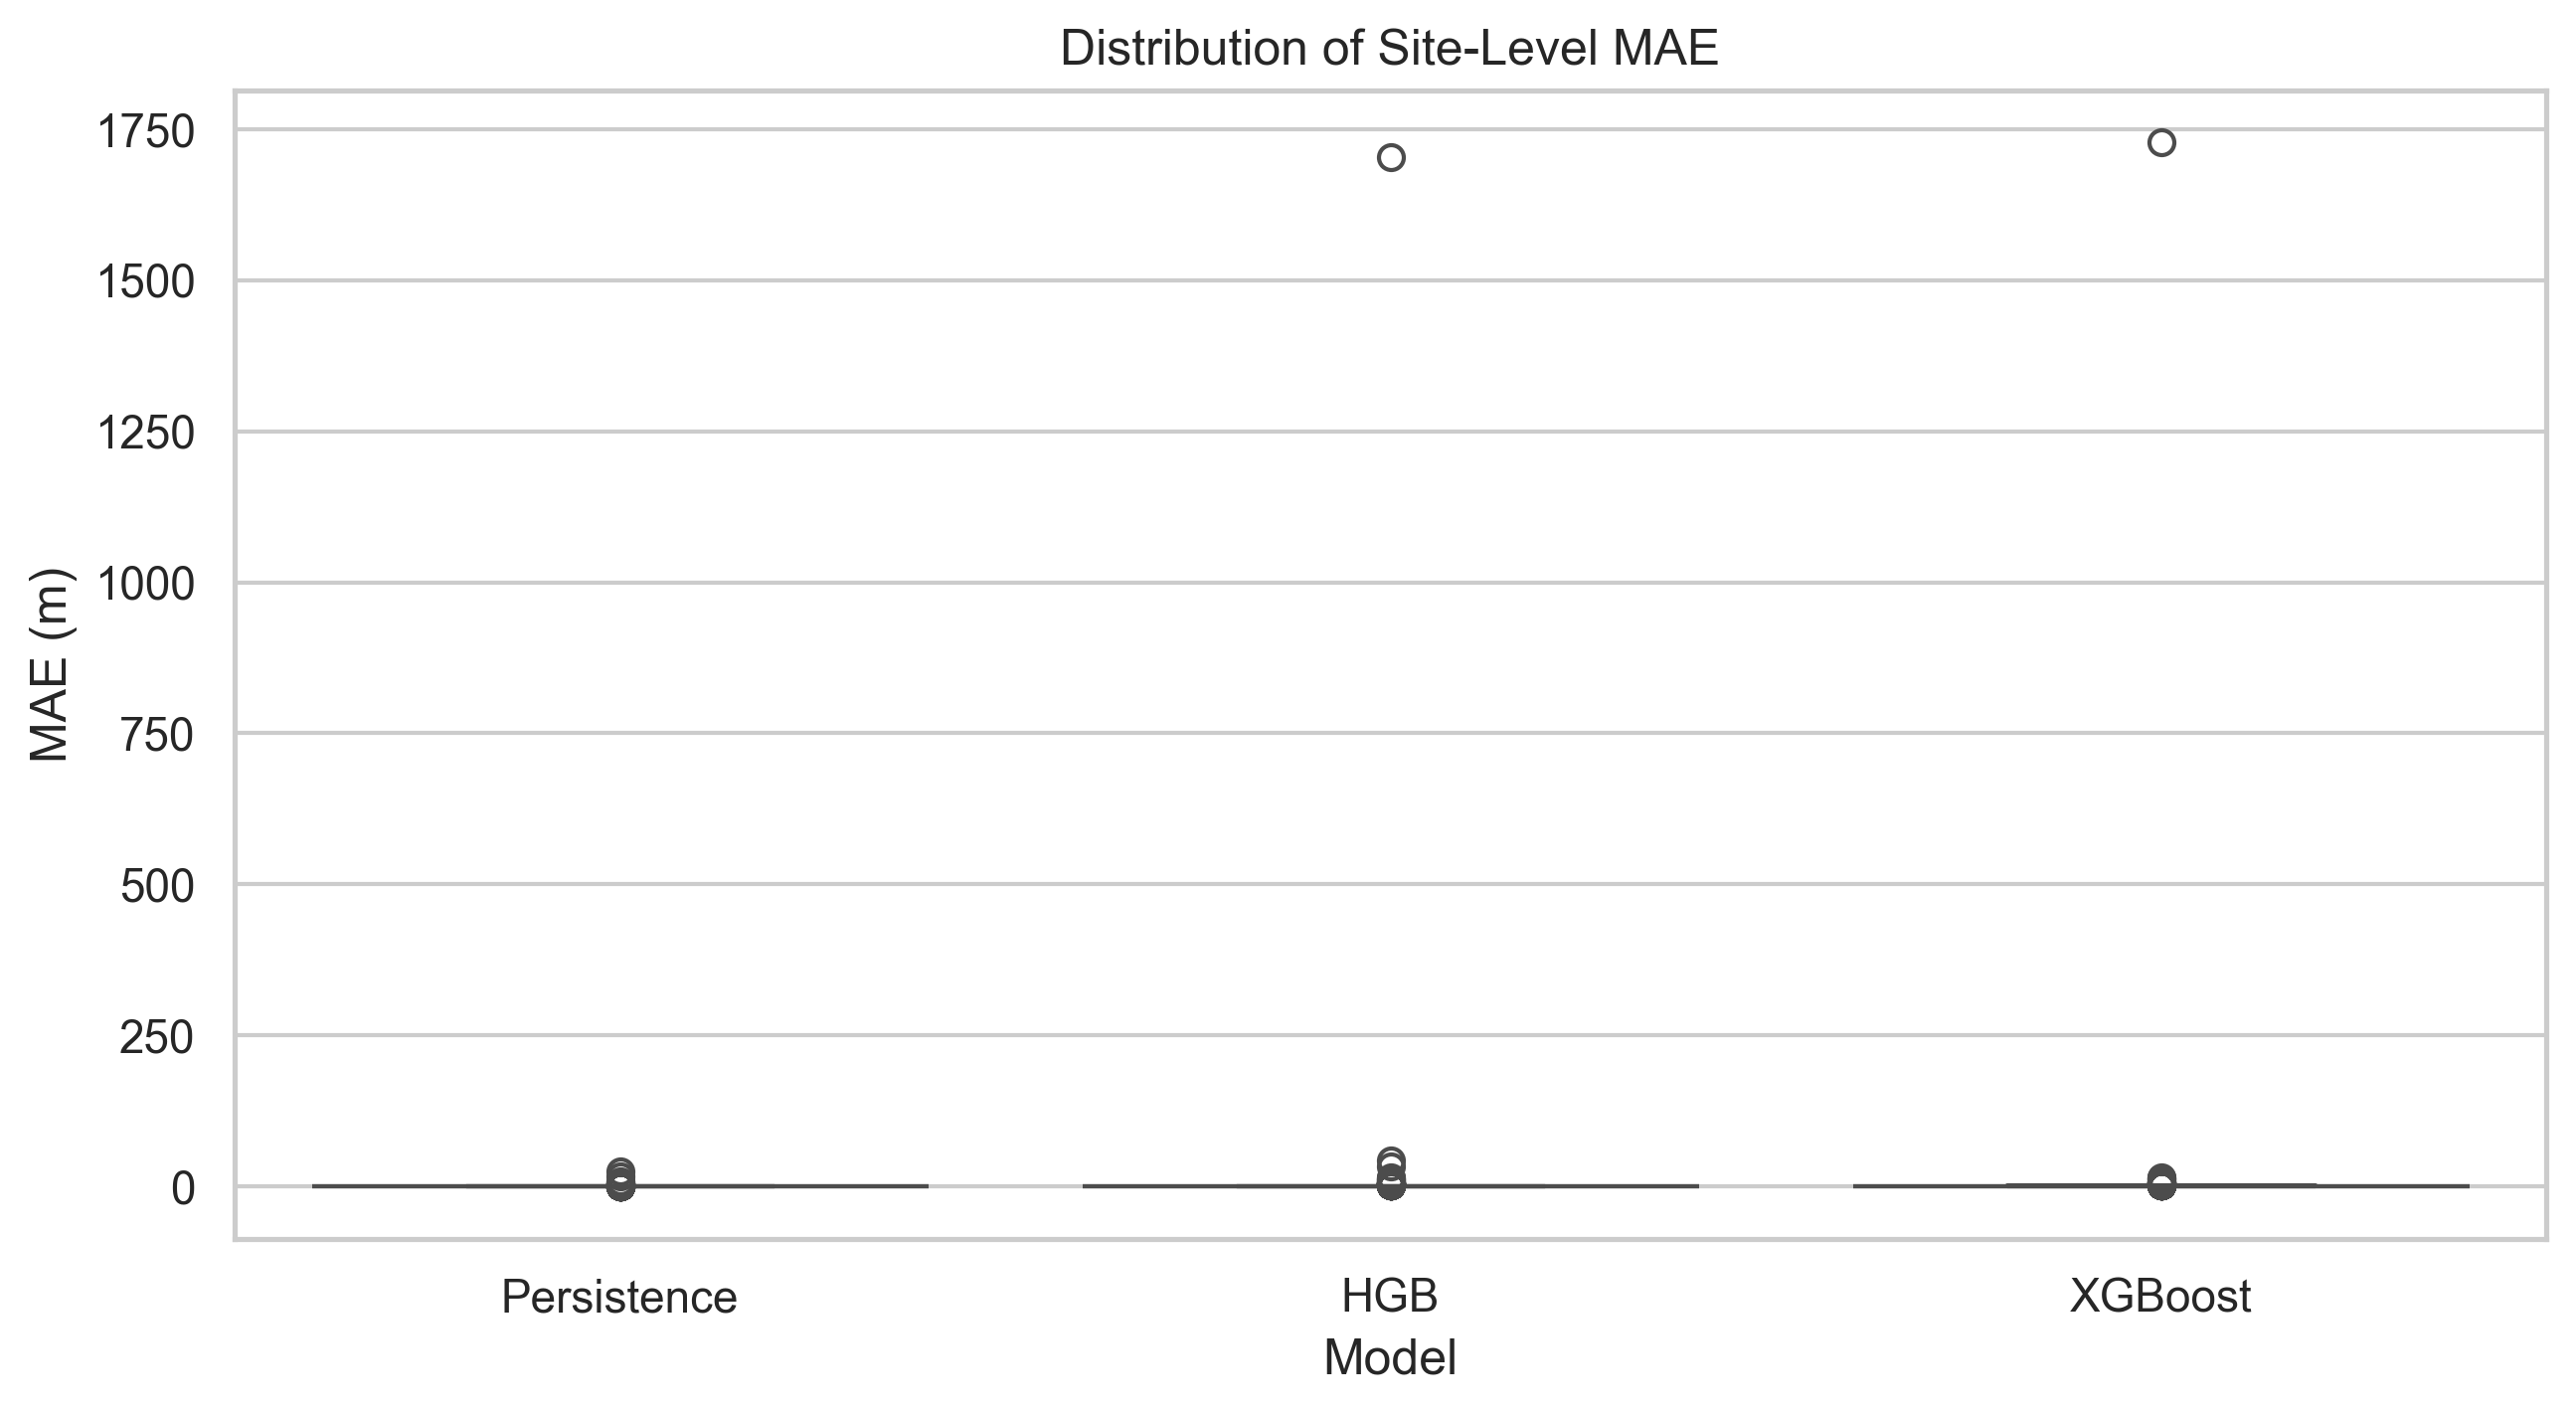

In [17]:
site_metrics = []
for site, grp in test_df.groupby("candidate_site_id"):
    if len(grp) < 5: continue  # exclude extremely small samples
    for m in models:
        site_metrics.append({
            "Site": site,
            "Model": m,
            "MAE (m)": mean_absolute_error(grp["target_water_level"], grp[f"pred_{m}"]),
            "N": len(grp)
        })

site_df = pd.DataFrame(site_metrics)
if not site_df.empty:
    site_df.to_csv(TABLES_DIR / "site_level_metrics.csv", index=False)
    plt.figure(figsize=(10, 5))
    sns.boxplot(data=site_df, x="Model", y="MAE (m)")
    plt.title("Distribution of Site-Level MAE")
    plt.savefig(FIGURES_DIR / "10_site_level_performance.png")
    plt.show()


## 14. Performance by Month

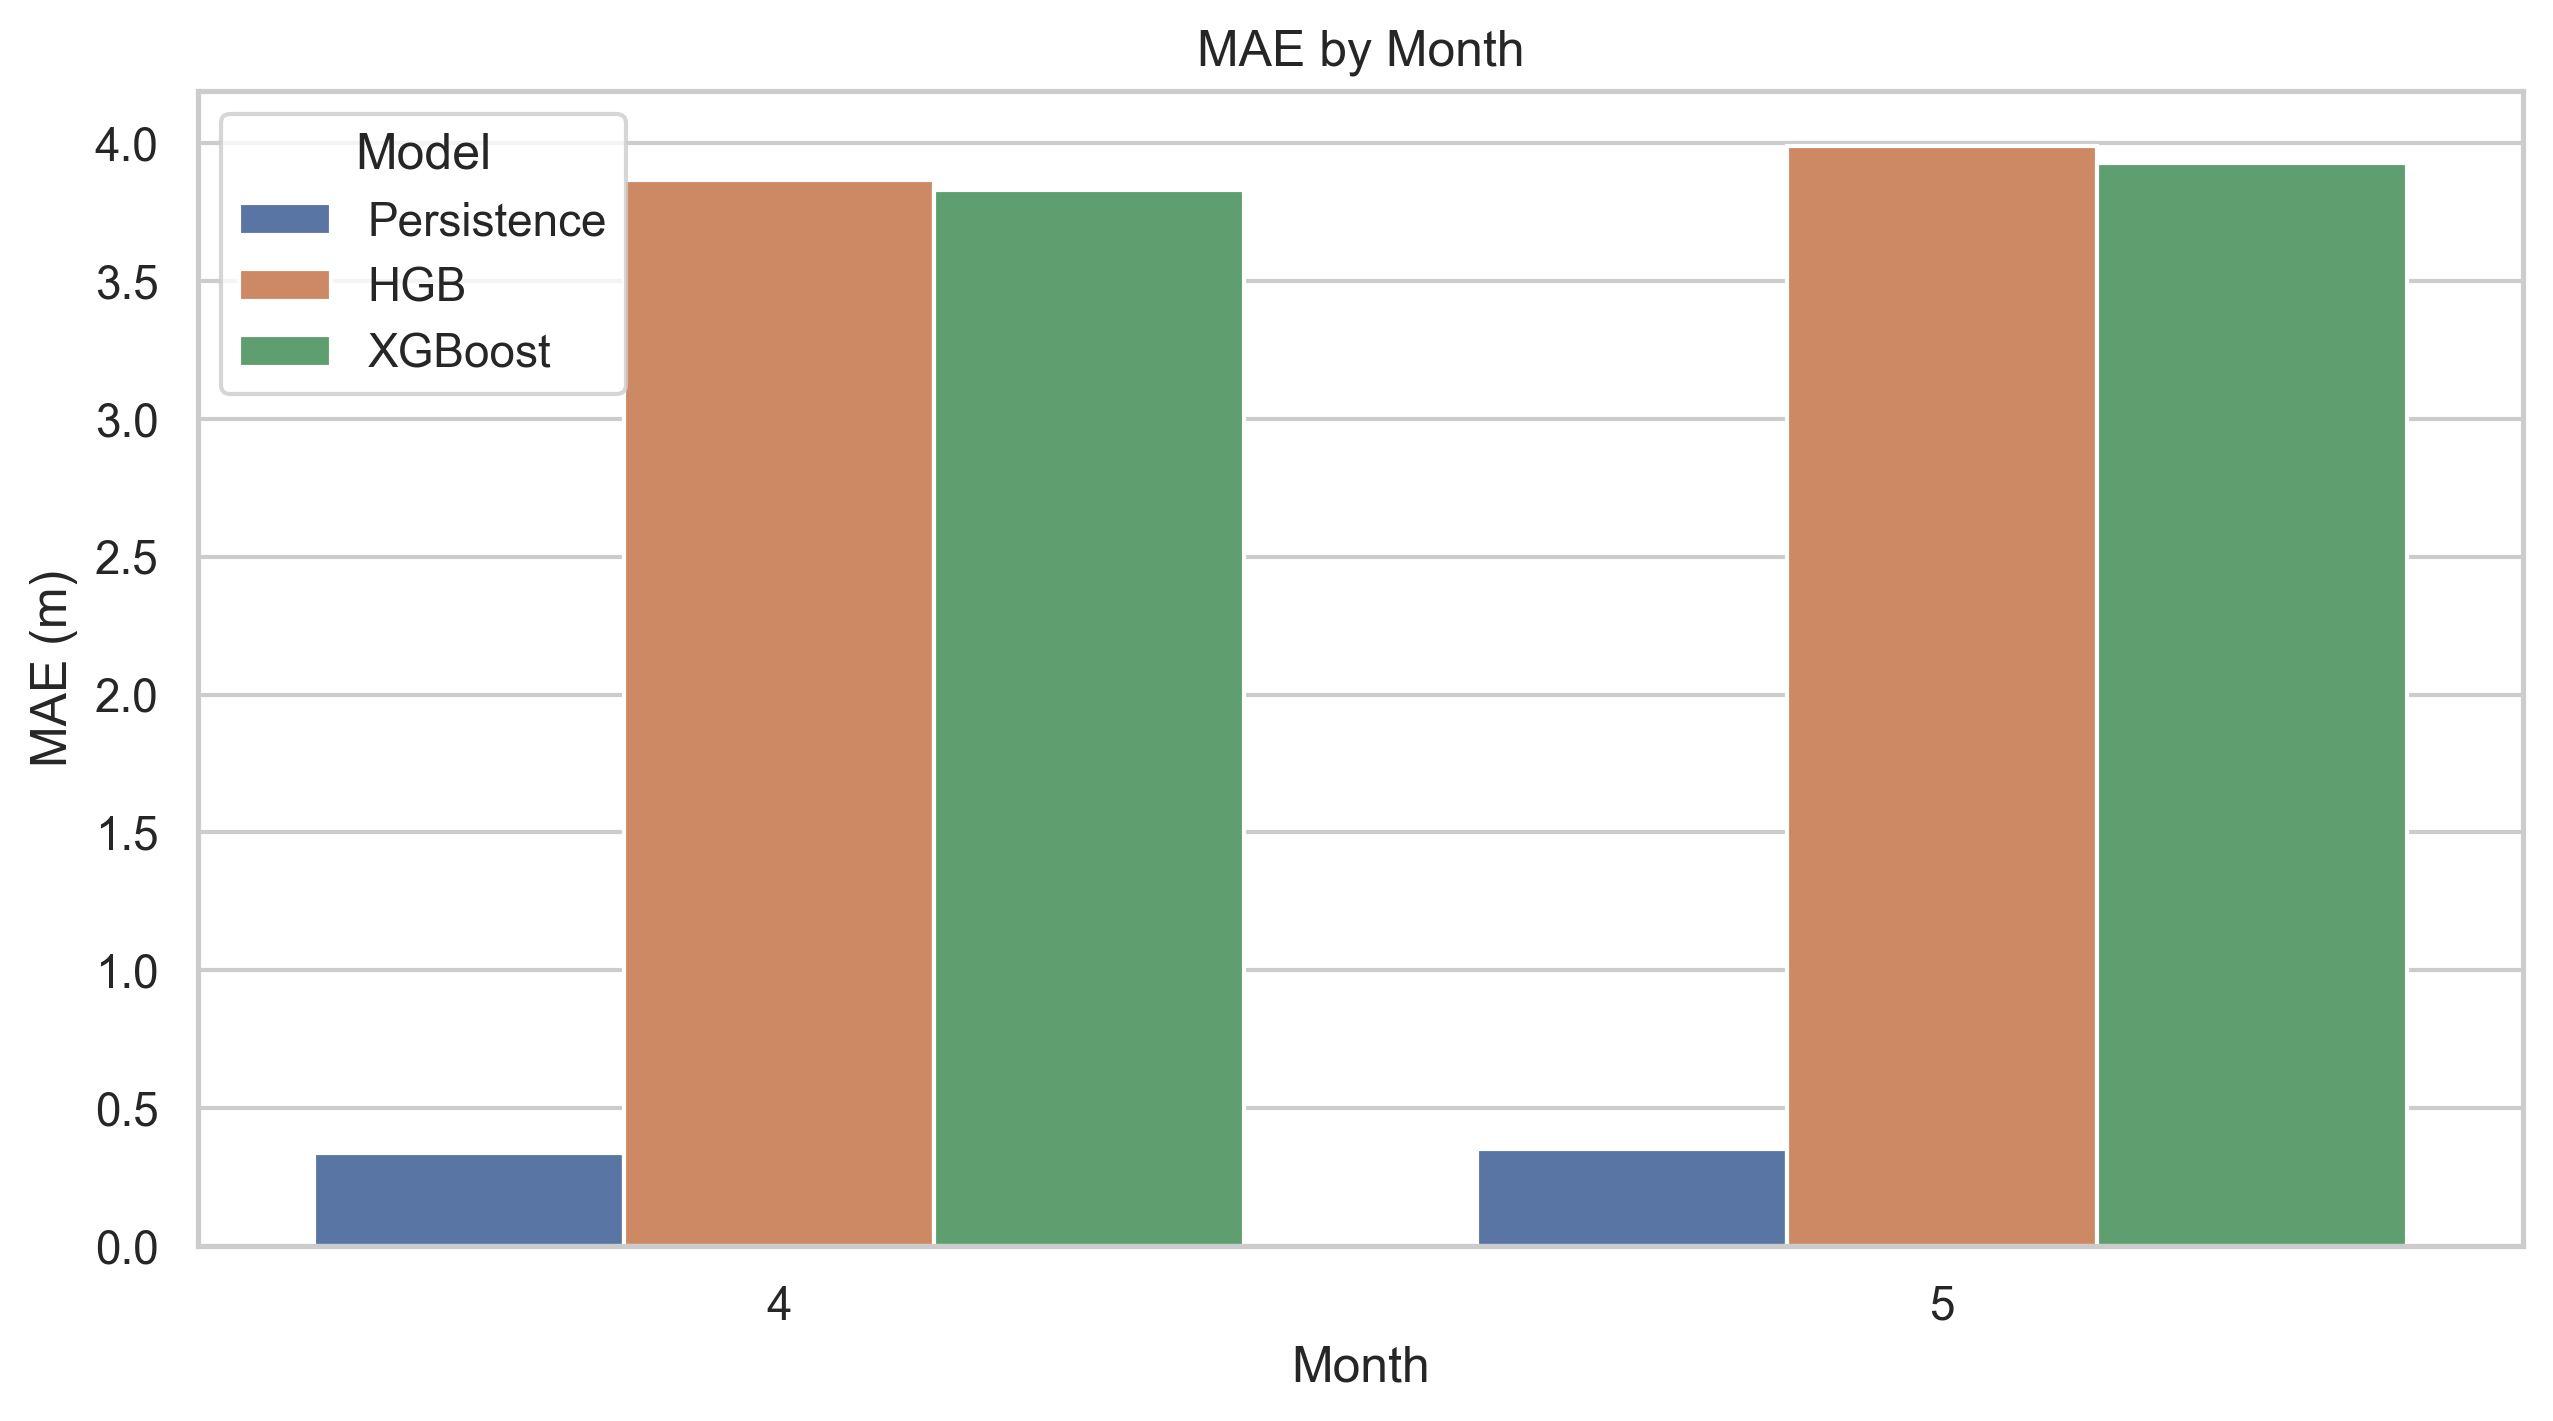

In [18]:
test_df["month"] = test_df["target_dt"].dt.month
monthly_metrics = []
for mo, grp in test_df.groupby("month"):
    for m in models:
        res = calc_metrics(grp["target_water_level"], grp[f"pred_{m}"], m)
        res["Month"] = mo
        monthly_metrics.append(res)
        
mo_df = pd.DataFrame(monthly_metrics)
mo_df.to_csv(TABLES_DIR / "monthly_metrics.csv", index=False)

plt.figure(figsize=(10, 5))
sns.barplot(data=mo_df, x="Month", y="MAE (m)", hue="Model")
plt.title("MAE by Month")
plt.savefig(FIGURES_DIR / "11_monthly_performance.png")
plt.show()


## 15. Extreme Error Audit & 16. Model Error Contribution

In [19]:
extreme_audit = []
for m in models:
    errs = test_df[f"abs_error_{m}"]
    total_rmse = np.sqrt(mean_squared_error(test_df["target_water_level"], test_df[f"pred_{m}"]))
    clean_mask = errs <= 5
    if len(test_df[clean_mask]) > 0:
        clean_rmse = np.sqrt(mean_squared_error(test_df.loc[clean_mask, "target_water_level"], test_df.loc[clean_mask, f"pred_{m}"]))
    else:
        clean_rmse = total_rmse
        
    extreme_audit.append({
        "Model": m,
        "Errors > 1m": (errs > 1).sum(),
        "Errors > 2m": (errs > 2).sum(),
        "Errors > 5m": (errs > 5).sum(),
        "Max Error (m)": errs.max(),
        "Official RMSE": total_rmse,
        "Diagnostic RMSE (exclude >5m)": clean_rmse,
        "RMSE Change": total_rmse - clean_rmse
    })

audit_df = pd.DataFrame(extreme_audit)
audit_df.to_csv(TABLES_DIR / "extreme_error_audit.csv", index=False)
display(audit_df)


,Model,Errors > 1m,Errors > 2m,Errors > 5m,Max Error (m),Official RMSE,Diagnostic RMSE (exclude >5m),RMSE Change
0,Persistence,1459,733,319,221.860000,4.246217,0.464504,3.781713
1,HGB,3514,2108,1038,1774.184834,73.494669,0.716449,72.778219
2,XGBoost,4219,1959,763,1737.476498,74.510377,0.798878,73.711499


## 17. Model Bias

,Model,Mean Error (m),Median Error (m),Positive Error %,Negative Error %
0,Persistence,-0.004199,0.000000,46.089153,33.947301
1,HGB,3.165757,-0.004658,48.548222,51.451778
2,XGBoost,3.253948,-0.019341,46.249041,53.750959


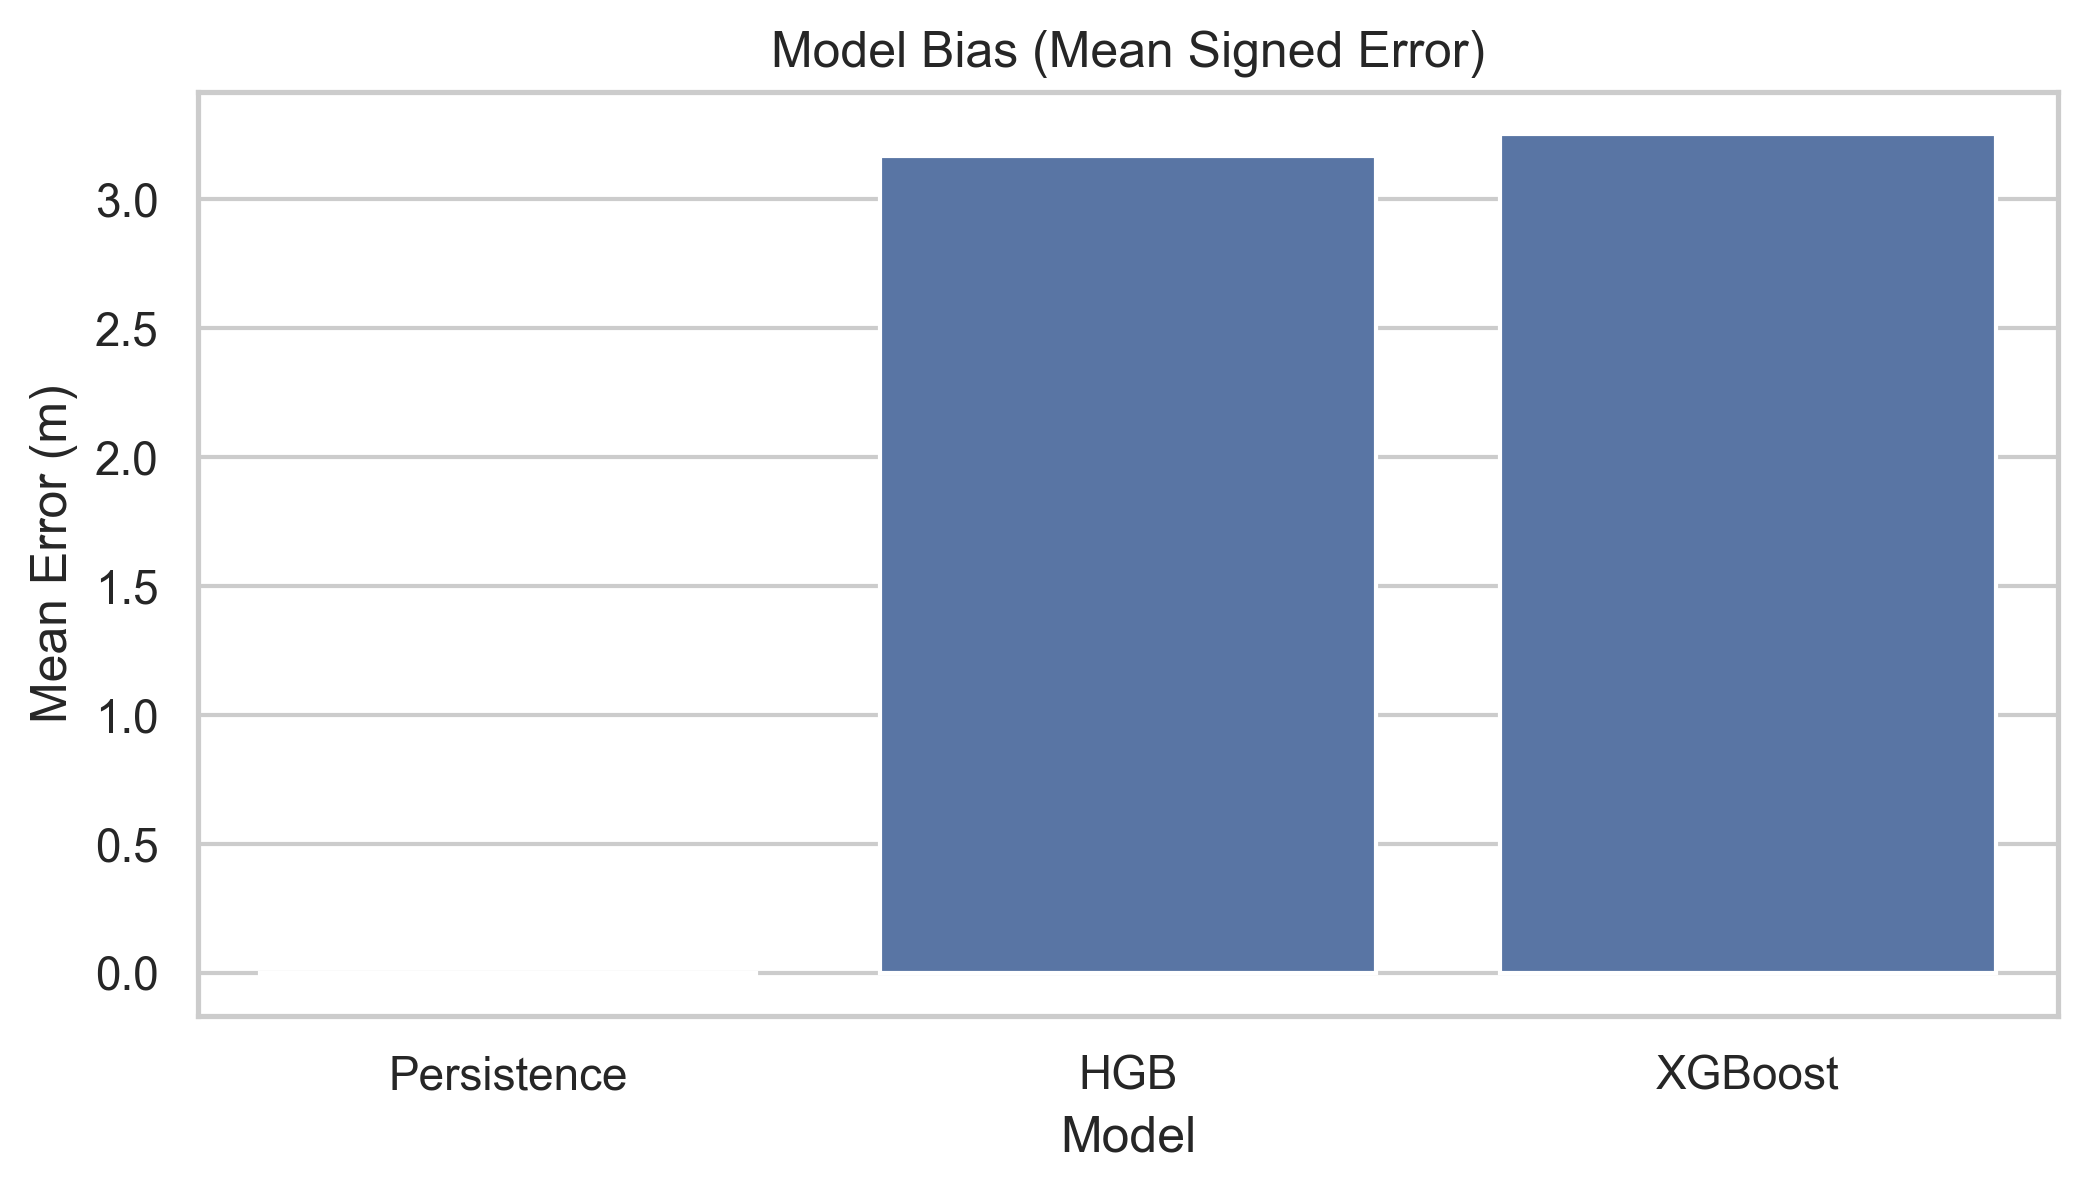

In [20]:
bias_metrics = []
for m in models:
    errs = test_df[f"error_{m}"]
    bias_metrics.append({
        "Model": m,
        "Mean Error (m)": errs.mean(),
        "Median Error (m)": errs.median(),
        "Positive Error %": (errs > 0).mean() * 100,
        "Negative Error %": (errs < 0).mean() * 100
    })

bias_df = pd.DataFrame(bias_metrics)
bias_df.to_csv(TABLES_DIR / "bias_metrics.csv", index=False)
display(bias_df)

plt.figure(figsize=(8, 4))
sns.barplot(data=bias_df, x="Model", y="Mean Error (m)")
plt.title("Model Bias (Mean Signed Error)")
plt.savefig(FIGURES_DIR / "14_bias_comparison.png")
plt.show()


## 18. Baseline Relative Improvement

In [21]:
base_mae = overall_metrics.set_index("Model").loc["Persistence", "MAE (m)"]
base_rmse = overall_metrics.set_index("Model").loc["Persistence", "RMSE (m)"]

imp_metrics = []
for m in models:
    m_mae = overall_metrics.set_index("Model").loc[m, "MAE (m)"]
    m_rmse = overall_metrics.set_index("Model").loc[m, "RMSE (m)"]
    
    imp_metrics.append({
        "Model": m,
        "MAE": m_mae,
        "MAE vs Persistence (%)": ((base_mae - m_mae) / base_mae) * 100 if m != "Persistence" else 0.0,
        "RMSE": m_rmse,
        "RMSE vs Persistence (%)": ((base_rmse - m_rmse) / base_rmse) * 100 if m != "Persistence" else 0.0
    })

imp_df = pd.DataFrame(imp_metrics)
imp_df.to_csv(TABLES_DIR / "baseline_comparison.csv", index=False)
display(imp_df)


,Model,MAE,MAE vs Persistence (%),RMSE,RMSE vs Persistence (%)
0,Persistence,0.348351,0.000000,4.246217,0.000000
1,HGB,3.969415,-1039.486366,73.494669,-1630.827092
2,XGBoost,3.910332,-1022.525758,74.510377,-1654.747405


## 19. Interpretation & 20. Model Ranking

In [22]:
ranking = overall_metrics.copy().reset_index(drop=True)
ranking.index += 1
ranking["Rank"] = ranking.index
ranking.to_csv(TABLES_DIR / "model_ranking.csv", index=False)
display(ranking)


,Model,MAE (m),MedAE (m),RMSE (m),R²,N,Rank
1,Persistence,0.348351,0.020000,4.246217,0.997044,31272,1
2,XGBoost,3.910332,0.179070,74.510377,0.089755,31272,2
3,HGB,3.969415,0.097577,73.494669,0.114402,31272,3


## 21. Production Decision & Final Executive Summary

In [23]:

best_ml = ranking[ranking["Model"] != "Persistence"].iloc[0]
persistence = ranking[ranking["Model"] == "Persistence"].iloc[0]

ml_wins = best_ml["MAE (m)"] < persistence["MAE (m)"]

if ml_wins:
    decision = "Experimental ML out-performed persistence on MAE. However, due to sparsity and robustness requirements, persistence is usually preferred unless the margin is transformative."
else:
    decision = "Persistence remains the preferred production forecasting method under the evaluated methodology."

summary_dict = {
    "evaluation_dataset": "Maharashtra Next Valid Observation",
    "observation_counts": total_observations,
    "test_rows": len(test_df),
    "median_target_gap_hours": df_raw["target_gap_hours"].median(),
    "production_model": "Persistence",
    "best_ml_model": best_ml["Model"],
    "persistence_mae": persistence["MAE (m)"],
    "best_ml_mae": best_ml["MAE (m)"],
    "persistence_rmse": persistence["RMSE (m)"],
    "best_ml_rmse": best_ml["RMSE (m)"],
    "production_recommendation": decision,
    "notebook_generation_timestamp": datetime.now().isoformat()
}

with open(REPORT_DIR / "model_evaluation_summary.json", "w") as f:
    f.write(json.dumps(summary_dict, indent=2))

exec_summary = pd.DataFrame([
    {"Parameter": "Prediction target", "Result": "Next valid observation"},
    {"Parameter": "Geography", "Result": "Maharashtra"},
    {"Parameter": "Evaluation observations (Test)", "Result": len(test_df)},
    {"Parameter": "Median next-observation gap (h)", "Result": round(summary_dict["median_target_gap_hours"], 2)},
    {"Parameter": "Production model", "Result": "Persistence"},
    {"Parameter": "Persistence MAE (m)", "Result": round(persistence["MAE (m)"], 4)},
    {"Parameter": "Best ML MAE (m)", "Result": round(best_ml["MAE (m)"], 4)},
    {"Parameter": "Persistence RMSE (m)", "Result": round(persistence["RMSE (m)"], 4)},
    {"Parameter": "Production recommendation", "Result": decision}
])
display(exec_summary)

print("\n" + "="*50)
print("FINAL CONCLUSION")
print("="*50)
print(f"1. How good is the model? The persistence model achieves a MAE of {persistence['MAE (m)']:.3f}m on test.")
print(f"2. How does ML compare? Best ML ({best_ml['Model']}) achieved MAE {best_ml['MAE (m)']:.3f}m.")
print(f"3. Production Recommendation: {decision}")
print("="*50)

# Final assertions
assert_check(len(test_df) == len(test_df.dropna(subset=[f"pred_{m}" for m in models])), "No NaNs in final predictions.")
assert_check(len(test_df) > 0, "Test set has records.")

if validation_passed:
    print("\nMODEL EVALUATION VALIDATION: PASSED")
else:
    print("\nMODEL EVALUATION VALIDATION: FAILED")


,Parameter,Result
0,Prediction target,Next valid observation
1,Geography,Maharashtra
2,Evaluation observations (Test),31272
3,Median next-observation gap (h),6.0
4,Production model,Persistence
5,Persistence MAE (m),0.3484
6,Best ML MAE (m),3.9103
7,Persistence RMSE (m),4.2462
8,Production recommendation,Persistence remains the preferred production f...



FINAL CONCLUSION
1. How good is the model? The persistence model achieves a MAE of 0.348m on test.
2. How does ML compare? Best ML (XGBoost) achieved MAE 3.910m.
3. Production Recommendation: Persistence remains the preferred production forecasting method under the evaluated methodology.
PASS: No NaNs in final predictions.
PASS: Test set has records.

MODEL EVALUATION VALIDATION: PASSED
